In [3]:
import sys
print(sys.executable)

C:\Users\Meghana gundu\Desktop\hylogger\.venv\Scripts\python.exe


In [4]:
import sys
print(sys.executable)

C:\Users\Meghana gundu\Desktop\hylogger\.venv\Scripts\python.exe


In [5]:
from pytsg import parse_tsg

print("pytsg successfully imported!")

pytsg successfully imported!


In [6]:
import sys
import pandas as pd
import numpy as np
import requests
import re

from pytsg import parse_tsg

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("pyTSG imported successfully")

Python: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
pandas: 3.0.5
numpy: 2.4.6
pyTSG imported successfully


### Step 2 — Read and clean the NVCL catalog


In [7]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
print(PROJECT_ROOT)


C:\Users\Meghana gundu\Desktop\hylogger


In [8]:
catalog_path = PROJECT_ROOT / "NVCL_WA_Catalog.xlsx"
vocab_path = PROJECT_ROOT / "Hylogger_vocab_working_20260731.xlsx"

print("NVCL catalog exists:", catalog_path.exists())
print("Vocabulary exists:", vocab_path.exists())

NVCL catalog exists: True
Vocabulary exists: True


In [11]:
catalog_raw = pd.read_excel(catalog_path)

print("Shape:", catalog_raw.shape)
catalog_raw.head(10)

Shape: (1952, 11)


,Dataset,Size,Last Modified,HoleName,SQL,Source,Reference Number,Unnamed: 7,Unnamed: 8,Confidentiality,Unnamed: 10
0,Folder WA,Size,Last Modified,HoleName,WHERE [CompanyHoleId] IN (,NaN,Anumber,CollarId,BoreholeId,WAMEX Open file / Confidential,WAPIMS Open file / Confidential
1,KD1.zip,415.1 Mbytes,2022-06-23T05:03:40Z,KD1,"'KD1',",WAMEX,173,4634435,NaN,OPEN FILE,NaN
2,MPWD10.zip,810.7 Mbytes,2022-06-23T05:04:22Z,MPWD10,"'MPWD10',",WAMEX,4394,4594776,NaN,OPEN FILE,NaN
3,MPWD11.zip,800.7 Mbytes,2022-06-23T05:03:47Z,MPWD11,"'MPWD11',",WAMEX,4394,4594777,NaN,OPEN FILE,NaN
4,MPWD12.zip,565.4 Mbytes,2022-06-23T04:58:13Z,MPWD12,"'MPWD12',",WAMEX,4394,4594778,NaN,OPEN FILE,NaN
5,MPWD3.zip,424.5 Mbytes,2022-06-23T04:53:57Z,MPWD3,"'MPWD3',",WAMEX,4394,4594779,NaN,OPEN FILE,NaN
6,MPWD6.zip,356.5 Mbytes,2022-06-23T05:03:23Z,MPWD6,"'MPWD6',",WAMEX,4394,4594782,NaN,OPEN FILE,NaN
7,MPWD7.zip,873.7 Mbytes,2022-06-23T05:02:45Z,MPWD7,"'MPWD7',",WAMEX,4394,4594783,NaN,OPEN FILE,NaN
8,MPWD73.zip,349.5 Mbytes,2022-06-23T05:02:16Z,MPWD73,"'MPWD73',",WAMEX,4394,4594784,NaN,OPEN FILE,NaN
9,MPWD74.zip,345.9 Mbytes,2022-06-23T05:06:22Z,MPWD74,"'MPWD74',",WAMEX,4394,4594785,NaN,OPEN FILE,NaN


In [12]:
catalog = catalog_raw.iloc[1:].copy()

catalog.reset_index(drop=True, inplace=True)

print("Cleaned shape:", catalog.shape)
catalog.head()


Cleaned shape: (1951, 11)


,Dataset,Size,Last Modified,HoleName,SQL,Source,Reference Number,Unnamed: 7,Unnamed: 8,Confidentiality,Unnamed: 10
0,KD1.zip,415.1 Mbytes,2022-06-23T05:03:40Z,KD1,"'KD1',",WAMEX,173,4634435,NaN,OPEN FILE,NaN
1,MPWD10.zip,810.7 Mbytes,2022-06-23T05:04:22Z,MPWD10,"'MPWD10',",WAMEX,4394,4594776,NaN,OPEN FILE,NaN
2,MPWD11.zip,800.7 Mbytes,2022-06-23T05:03:47Z,MPWD11,"'MPWD11',",WAMEX,4394,4594777,NaN,OPEN FILE,NaN
3,MPWD12.zip,565.4 Mbytes,2022-06-23T04:58:13Z,MPWD12,"'MPWD12',",WAMEX,4394,4594778,NaN,OPEN FILE,NaN
4,MPWD3.zip,424.5 Mbytes,2022-06-23T04:53:57Z,MPWD3,"'MPWD3',",WAMEX,4394,4594779,NaN,OPEN FILE,NaN


In [13]:
catalog = catalog.rename(columns={
    "Dataset": "dataset",
    "Size": "size",
    "Last Modified": "last_modified",
    "HoleName": "hole_name",
    "SQL": "sql_name",
    "Source": "source",
    "Reference Number": "reference_number",
    "Unnamed: 7": "collar_id",
    "Unnamed: 8": "borehole_id",
    "Confidentiality": "wamex_confidentiality",
    "Unnamed: 10": "wapims_confidentiality"
})

catalog.columns
catalog[
    [
        "dataset",
        "hole_name",
        "source",
        "reference_number",
        "collar_id",
        "wamex_confidentiality"
    ]
].head(10)

,dataset,hole_name,source,reference_number,collar_id,wamex_confidentiality
0,KD1.zip,KD1,WAMEX,173,4634435,OPEN FILE
1,MPWD10.zip,MPWD10,WAMEX,4394,4594776,OPEN FILE
2,MPWD11.zip,MPWD11,WAMEX,4394,4594777,OPEN FILE
3,MPWD12.zip,MPWD12,WAMEX,4394,4594778,OPEN FILE
4,MPWD3.zip,MPWD3,WAMEX,4394,4594779,OPEN FILE
5,MPWD6.zip,MPWD6,WAMEX,4394,4594782,OPEN FILE
6,MPWD7.zip,MPWD7,WAMEX,4394,4594783,OPEN FILE
7,MPWD73.zip,MPWD73,WAMEX,4394,4594784,OPEN FILE
8,MPWD74.zip,MPWD74,WAMEX,4394,4594785,OPEN FILE
9,MPWD8.zip,MPWD8,WAMEX,4394,4594786,OPEN FILE


In [14]:
def size_to_mb(value):
    if pd.isna(value):
        return np.nan

    text = str(value).replace("\xa0", " ").strip()

    match = re.search(
        r"([\d.]+)\s*([KMG]?)bytes",
        text,
        flags=re.IGNORECASE
    )

    if not match:
        return np.nan

    number = float(match.group(1))
    unit = match.group(2).upper()

    if unit == "K":
        return number / 1024

    elif unit == "M":
        return number

    elif unit == "G":
        return number * 1024

    else:
        return number / (1024 * 1024)

In [15]:
catalog["size_mb"] = catalog["size"].apply(size_to_mb)

catalog[
    ["dataset", "hole_name", "size", "size_mb"]
].head()

,dataset,hole_name,size,size_mb
0,KD1.zip,KD1,415.1 Mbytes,415.1
1,MPWD10.zip,MPWD10,810.7 Mbytes,810.7
2,MPWD11.zip,MPWD11,800.7 Mbytes,800.7
3,MPWD12.zip,MPWD12,565.4 Mbytes,565.4
4,MPWD3.zip,MPWD3,424.5 Mbytes,424.5


In [16]:
open_file_catalog = catalog[
    catalog["wamex_confidentiality"]
    .astype(str)
    .str.contains("OPEN FILE", case=False, na=False)
].copy()

print("Number of WAMEX open-file datasets:")
print(len(open_file_catalog))
open_file_catalog.head()

Number of WAMEX open-file datasets:
1212


,dataset,size,last_modified,hole_name,sql_name,source,reference_number,collar_id,borehole_id,wamex_confidentiality,wapims_confidentiality,size_mb
0,KD1.zip,415.1 Mbytes,2022-06-23T05:03:40Z,KD1,"'KD1',",WAMEX,173,4634435,NaN,OPEN FILE,NaN,415.1
1,MPWD10.zip,810.7 Mbytes,2022-06-23T05:04:22Z,MPWD10,"'MPWD10',",WAMEX,4394,4594776,NaN,OPEN FILE,NaN,810.7
2,MPWD11.zip,800.7 Mbytes,2022-06-23T05:03:47Z,MPWD11,"'MPWD11',",WAMEX,4394,4594777,NaN,OPEN FILE,NaN,800.7
3,MPWD12.zip,565.4 Mbytes,2022-06-23T04:58:13Z,MPWD12,"'MPWD12',",WAMEX,4394,4594778,NaN,OPEN FILE,NaN,565.4
4,MPWD3.zip,424.5 Mbytes,2022-06-23T04:53:57Z,MPWD3,"'MPWD3',",WAMEX,4394,4594779,NaN,OPEN FILE,NaN,424.5


In [17]:
small_datasets = (
    open_file_catalog
    .sort_values("size_mb")
    [
        [
            "dataset",
            "hole_name",
            "size_mb",
            "source",
            "reference_number",
            "collar_id"
        ]
    ]
)

small_datasets.head(20)

,dataset,hole_name,size_mb,source,reference_number,collar_id
845,PLWDD005.zip,PLWDD005,9.509,WAMEX,112432,3991007
686,LYRM03.zip,LYRM03,10.390,WAMEX,104799,3690556
689,LYRM06.zip,LYRM06,10.650,WAMEX,104799,3690559
833,PLWDD001.zip,PLWDD001,10.780,WAMEX,110741,3988628
684,LYRM01.zip,LYRM01,10.860,WAMEX,104799,3690554
692,LYRM09.zip,LYRM09,11.360,WAMEX,104799,3690562
685,LYRM02.zip,LYRM02,11.550,WAMEX,104799,3690555
688,LYRM05.zip,LYRM05,11.660,WAMEX,104799,3690558
479,LJM-D012.zip,LJM-D012,11.670,WAMEX,95248,2303387
690,LYRM07.zip,LYRM07,11.760,WAMEX,104799,3690560


In [18]:
pilot_hole = "PLWDD005"

pilot = catalog[
    catalog["hole_name"].astype(str).str.strip() == pilot_hole
].copy()

pilot.T

,845
dataset,PLWDD005.zip
size,9.509 Mbytes
last_modified,2022-06-23T04:55:14Z
hole_name,PLWDD005
sql_name,"'PLWDD005',"
source,WAMEX
reference_number,112432
collar_id,3991007
borehole_id,NaN
wamex_confidentiality,OPEN FILE


In [19]:
DATA_DIR = PROJECT_ROOT / "data"

RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
CATALOG_DIR = DATA_DIR / "catalog"

RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
CATALOG_DIR.mkdir(parents=True, exist_ok=True)

print("Raw directory:", RAW_DIR)
print("Processed directory:", PROCESSED_DIR)
print("Catalog directory:", CATALOG_DIR)

Raw directory: C:\Users\Meghana gundu\Desktop\hylogger\data\raw
Processed directory: C:\Users\Meghana gundu\Desktop\hylogger\data\processed
Catalog directory: C:\Users\Meghana gundu\Desktop\hylogger\data\catalog


In [20]:
from pytsg import parse_tsg

### Step 3: download the pilot package, extract it, and inspect the real TSG files.

In [21]:
pilot_hole = "PLWDD005"
pilot_dataset = "PLWDD005.zip"

print("Pilot hole:", pilot_hole)
print("Dataset:", pilot_dataset)

Pilot hole: PLWDD005
Dataset: PLWDD005.zip


In [22]:
BASE_DOWNLOAD_URL = "https://thredds.nci.org.au/thredds/fileServer/rs07/WA"

download_url = f"{BASE_DOWNLOAD_URL}/{pilot_dataset}"

print(download_url)

https://thredds.nci.org.au/thredds/fileServer/rs07/WA/PLWDD005.zip


In [23]:
response = requests.head(
    download_url,
    allow_redirects=True,
    timeout=30
)

print("Status code:", response.status_code)
print("Content type:", response.headers.get("Content-Type"))
print("Content length:", response.headers.get("Content-Length"))


Status code: 404
Content type: text/html;charset=utf-8
Content length: 768


In [24]:
pilot_raw_dir = RAW_DIR / pilot_hole
pilot_raw_dir.mkdir(parents=True, exist_ok=True)

zip_path = pilot_raw_dir / pilot_dataset

print("Download location:")
print(zip_path)

Download location:
C:\Users\Meghana gundu\Desktop\hylogger\data\raw\PLWDD005\PLWDD005.zip


In [25]:
def download_file(url, destination, chunk_size=1024 * 1024):
    destination = Path(destination)

    with requests.get(url, stream=True, timeout=120) as response:
        response.raise_for_status()

        total_size = response.headers.get("Content-Length")

        if total_size is not None:
            total_size = int(total_size)
            print(f"Expected download size: {total_size / 1024**2:.2f} MB")

        with open(destination, "wb") as f:
            downloaded = 0

            for chunk in response.iter_content(chunk_size=chunk_size):
                if chunk:
                    f.write(chunk)
                    downloaded += len(chunk)

                    print(
                        f"\rDownloaded: {downloaded / 1024**2:.2f} MB",
                        end=""
                    )

    print("\nDownload complete.")

In [26]:
download_file(download_url, zip_path)

HTTPError: 404 Client Error: 404 for url: https://thredds.nci.org.au/thredds/fileServer/rs07/WA/PLWDD005.zip

In [27]:
print("File exists:", zip_path.exists())

if zip_path.exists():
    size_mb = zip_path.stat().st_size / 1024**2
    print(f"Downloaded file size: {size_mb:.2f} MB")

File exists: True
Downloaded file size: 9.07 MB


In [113]:
# First extraction event successful

In [28]:
import zipfile

print("Valid ZIP:", zipfile.is_zipfile(zip_path))
with zipfile.ZipFile(zip_path, "r") as z:
    zip_files = z.namelist()

print("Number of files inside:", len(zip_files))

for filename in zip_files:
    print(filename)

Valid ZIP: True
Number of files inside: 13
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_0001.jpg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg.cal
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg.ini
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg.tsg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_1.ini
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_cras.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_hires.dat
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_Mosaic.jpg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_tir.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_tir.cal
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_tir.ini
d6aa96f9-cd39-4eda-9392-f1c1b3b8735/PLWDD005_tsg_tir.tsg


In [29]:
extract_dir = pilot_raw_dir / "extracted"
extract_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Extracted to:")
print(extract_dir)
for path in extract_dir.rglob("*"):
    if path.is_file():
        print(path.relative_to(extract_dir))

Extracted to:
C:\Users\Meghana gundu\Desktop\hylogger\data\raw\PLWDD005\extracted
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_0001.jpg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.cal
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.ini
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.tsg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_1.ini
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_cras.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_hires.dat
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_Mosaic.jpg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_tir.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_tir.cal
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_tir.ini
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_tir.tsg


In [30]:
tsg_related_extensions = {
    ".tsg",
    ".bip",
    ".dat",
    ".csv",
    ".txt",
    ".jpg",
    ".jpeg",
    ".png"
}

tsg_files = [
    path
    for path in extract_dir.rglob("*")
    if path.is_file()
    and path.suffix.lower() in tsg_related_extensions
]

print(f"Found {len(tsg_files)} potentially relevant files:\n")

for path in tsg_files:
    print(path.relative_to(extract_dir))

Found 8 potentially relevant files:

d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_0001.jpg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.tsg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_cras.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_hires.dat
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_Mosaic.jpg
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_tir.bip
d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg_tir.tsg


In [31]:
primary_tsg_files = list(extract_dir.rglob("*_tsg.tsg"))

print("Primary TSG files found:", len(primary_tsg_files))

for path in primary_tsg_files:
    print(path)
primary_tsg = primary_tsg_files[0]

tsg_package_dir = primary_tsg.parent

print("pyTSG package directory:")
print(tsg_package_dir) 
data = parse_tsg.read_package(str(tsg_package_dir))

print("TSG package successfully parsed!")

Primary TSG files found: 1
C:\Users\Meghana gundu\Desktop\hylogger\data\raw\PLWDD005\extracted\d6aa96f9-cd39-4eda-9392-f1c1b3b8735\PLWDD005_tsg.tsg
pyTSG package directory:
C:\Users\Meghana gundu\Desktop\hylogger\data\raw\PLWDD005\extracted\d6aa96f9-cd39-4eda-9392-f1c1b3b8735
TSG package successfully parsed!


In [32]:
print(type(data))
print(dir(data))

<class 'pytsg.parse_tsg.TSG'>
['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'cras', 'lidar', 'mir', 'nir', 'tir']


In [33]:
if hasattr(data, "nir") and data.nir is not None:
    print("NIR available")
    print("NIR type:", type(data.nir))

    print("\nNIR attributes:")
    print(dir(data.nir))
else:
    print("No NIR data found")
if hasattr(data, "nir") and data.nir is not None:
    print("Wavelength shape:")
    print(np.shape(data.nir.wavelength))

    print("\nSpectra shape:")
    print(np.shape(data.nir.spectra))  
if hasattr(data, "tir") and data.tir is not None:
    print("TIR available")

    print("TIR wavelength shape:")
    print(np.shape(data.tir.wavelength))

    print("TIR spectra shape:")
    print(np.shape(data.tir.spectra))
else:
    print("No TIR data found")    

NIR available
NIR type: <class 'pytsg.parse_tsg.Spectra'>

NIR attributes:
['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'bandheaders', 'classes', 'sampleheaders', 'scalars', 'spectra', 'spectrum_name', 'wavelength']
Wavelength shape:
(531,)

Spectra shape:
(405, 531)
TIR available
TIR wavelength shape:
(341,)
TIR spectra shape:
(405, 341)


In [34]:
zip_files
print(dir(data))
print(dir(data.nir))
print(np.shape(data.nir.wavelength))
print(np.shape(data.nir.spectra))

['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'cras', 'lidar', 'mir', 'nir', 'tir']
['__annotations__', '__class__', '__dataclass_fields__', '__dataclass_params__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__match_args__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'bandheaders', 'classes', 'sampleheaders', 'scalars', 'spectra', 'spec

### Step 4 — Inspect the NIR metadata

In [35]:
print("sampleheaders:", type(data.nir.sampleheaders))
print("bandheaders:", type(data.nir.bandheaders))
print("classes:", type(data.nir.classes))
print("scalars:", type(data.nir.scalars))
print("spectrum_name:", type(data.nir.spectrum_name))
print("spectrum_name:")
print(data.nir.spectrum_name)

sampleheaders: <class 'pandas.DataFrame'>
bandheaders: <class 'list'>
classes: <class 'dict'>
scalars: <class 'pandas.DataFrame'>
spectrum_name: <class 'str'>
spectrum_name:
nir


In [36]:
print(data.nir.sampleheaders)
print("Shape:", np.shape(data.nir.sampleheaders))

    sample     T  L    P           D            X         H
0        0  0001  1    1  101.550007     4.000000  PLWDD005
1        1  0001  1    2  101.550007    12.000000  PLWDD005
2        2  0001  1    3  101.550006    20.000000  PLWDD005
3        3  0001  1    4  101.550006    28.000000  PLWDD005
4        4  0001  1    5  101.550006    36.000000  PLWDD005
..     ...   ... ..  ...         ...          ...       ...
400    400  0001  3  131  103.300004  1044.000000  PLWDD005
401    401  0001  3  132  103.300004  1052.000000  PLWDD005
402    402  0001  3  133  103.300004  1060.000000  PLWDD005
403    403  0001  3  134  103.300003  1068.000000  PLWDD005
404    404  0001  3  135  103.300003  1076.000000  PLWDD005

[405 rows x 7 columns]
Shape: (405, 7)


In [37]:
if isinstance(data.nir.sampleheaders, pd.DataFrame):
    display(data.nir.sampleheaders.head())
    print(data.nir.sampleheaders.columns.tolist())

,sample,T,L,P,D,X,H
0,0,0001,1,1,101.550007,4.000000,PLWDD005
1,1,0001,1,2,101.550007,12.000000,PLWDD005
2,2,0001,1,3,101.550006,20.000000,PLWDD005
3,3,0001,1,4,101.550006,28.000000,PLWDD005
4,4,0001,1,5,101.550006,36.000000,PLWDD005


['sample', 'T', 'L', 'P', 'D', 'X', 'H']


In [38]:
print("Classes type:", type(data.nir.classes))
print("Classes shape:", np.shape(data.nir.classes))
print(repr(data.nir.classes)[:5000])

Classes type: <class 'dict'>
Classes shape: ()
{0: ClassHeaders(class_number=0, name='Domain', max=1, classes={0: 'Default'}), 1: ClassHeaders(class_number=1, name='S_SWIR_TSA705 Groups', max=17, classes={0: 'SILICA', 1: 'KAOLIN', 2: 'WHITE-MICA', 3: 'SMECTITE', 4: 'OTHER-ALOH', 5: 'CHLORITE', 6: 'DARK-MICA', 7: 'AMPHIBOLE', 8: 'SERPENTINE', 9: 'OTHER-MGOH', 10: 'EPIDOTE', 11: 'TOURMALINE', 12: 'CARBONATE', 13: 'SULPHATE', 14: 'PAL-SEP', 15: 'NOTAROK', 16: 'INVALID'}), 2: ClassHeaders(class_number=2, name='S_VNIR_TSA704 Groups', max=8, classes={0: 'MISC-SILICATE', 1: 'CARBONATE', 2: 'SULPHATE', 3: 'OXIDE', 4: 'SULPHIDE', 5: 'CLAY-CU', 6: 'NOTAROK', 7: 'INVALID'}), 3: ClassHeaders(class_number=3, name='S_SWIR_TSA705 Minerals', max=61, classes={0: 'Opal', 1: 'Dickite', 2: 'Kaolinite-PX', 3: 'Kaolinite-WX', 4: 'Nacrite', 5: 'Muscovite', 6: 'Paragonite', 7: 'Phengite', 8: 'Montmorillonite', 9: 'Nontronite', 10: 'Saponite', 11: 'Diaspore', 12: 'Gibbsite', 13: 'Prehnite', 14: 'Pyrophyllite',

In [124]:
print("Scalars type:", type(data.nir.scalars))
print("Scalars shape:", np.shape(data.nir.scalars))
if isinstance(data.nir.scalars, pd.DataFrame):
    display(data.nir.scalars.head(20))
    print(data.nir.scalars.columns.tolist())

Scalars type: <class 'pandas.DataFrame'>
Scalars shape: (405, 126)


,Flags,FeatExMethod,NumFeats,Depth1,Centre1,Width1,Depth2,Centre2,Width2,Depth3,...,NIL_Stat sTSAV,SNR sTSAS,Wt3 sTSAS,Section,virtual_section,CustScore,prof_min,sec_end_mask,Error sTSAS,Min1 sTSAS
0,0.388889,0.0,25.0,0.018818,2464.000244,40.002567,0.019711,2404.000000,20.001284,0.051729,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,4.208183,0.0,-3.402823e+38,
1,1.350000,0.0,25.0,0.291802,2460.000000,64.004059,0.232193,2404.000000,52.003189,0.035512,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,45.762394,1.0,-3.402823e+38,
2,2.218750,0.0,25.0,0.136812,2460.000000,52.003189,0.014523,2428.000244,16.001074,0.051957,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,67.888260,1.0,-3.402823e+38,
3,3.013258,0.0,25.0,0.232567,2460.000000,72.004715,0.188287,2400.000000,56.003639,0.022477,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,70.117722,1.0,-3.402823e+38,
4,4.087500,0.0,25.0,0.171020,2464.000244,40.002567,0.049467,2428.000244,32.001907,0.314952,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,27.613674,1.0,-3.402823e+38,
5,5.388889,0.0,25.0,0.052993,2480.000000,36.002357,0.014440,2460.000000,20.001284,0.022482,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,1.425543,1.0,-3.402823e+38,
6,6.291667,0.0,24.0,0.055305,2480.000000,36.002357,0.015509,2456.000000,24.001728,0.018057,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,55.348900,1.0,-3.402823e+38,
7,7.025735,0.0,25.0,0.054629,2480.000000,36.002357,0.017211,2456.000000,20.001522,0.018620,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,56.693871,1.0,-3.402823e+38,
8,8.145833,0.0,24.0,0.055777,2480.000000,36.002357,0.014671,2456.000000,20.001522,0.021518,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,57.034294,1.0,-3.402823e+38,
9,9.350000,0.0,25.0,0.049703,2480.000000,36.002357,0.013708,2456.000000,20.001522,0.018357,...,-3.402823e+38,-3.402823e+38,-3.402823e+38,1.0,1.0,-3.402823e+38,57.309364,1.0,-3.402823e+38,


['Flags', 'FeatExMethod', 'NumFeats', 'Depth1', 'Centre1', 'Width1', 'Depth2', 'Centre2', 'Width2', 'Depth3', 'Centre3', 'Width3', 'Depth4', 'Centre4', 'Width4', 'Depth5', 'Centre5', 'Width5', 'Depth6', 'Centre6', 'Width6', 'Depth7', 'Centre7', 'Width7', 'Depth8', 'Centre8', 'Width8', 'Depth9', 'Centre9', 'Width9', 'Depth10', 'Centre10', 'Width10', 'Depth11', 'Centre11', 'Width11', 'Depth12', 'Centre12', 'Width12', 'Depth13', 'Centre13', 'Width13', 'Depth14', 'Centre14', 'Width14', 'Depth15', 'Centre15', 'Width15', 'Depth16', 'Centre16', 'Width16', 'Depth17', 'Centre17', 'Width17', 'Depth18', 'Centre18', 'Width18', 'Depth19', 'Centre19', 'Width19', 'Depth20', 'Centre20', 'Width20', 'Depth21', 'Centre21', 'Width21', 'Depth22', 'Centre22', 'Width22', 'Depth23', 'Centre23', 'Width23', 'Depth24', 'Centre24', 'Width24', 'Depth25', 'Centre25', 'Width25', 'Depth (m)', 'RelRange', 'Interactive Depth Logging', 'Domain', 'Grp1 sTSAS', 'TNorm sTSAS', 'Kahuna', 'Final Mask', 'SecSamp', 'Error sTSA

In [125]:
print("Bandheaders type:", type(data.nir.bandheaders))
print("Bandheaders shape:", np.shape(data.nir.bandheaders))
print(repr(data.nir.bandheaders)[:3000])

Bandheaders type: <class 'list'>
Bandheaders shape: (126, 4)
[BandHeaders(band=0, name='Flags', class_number=-1, flag=-1), BandHeaders(band=1, name='FeatExMethod', class_number=-1, flag=-1), BandHeaders(band=2, name='NumFeats', class_number=-1, flag=-1), BandHeaders(band=3, name='Depth1', class_number=-1, flag=-1), BandHeaders(band=4, name='Centre1', class_number=-1, flag=-1), BandHeaders(band=5, name='Width1', class_number=-1, flag=-1), BandHeaders(band=6, name='Depth2', class_number=-1, flag=-1), BandHeaders(band=7, name='Centre2', class_number=-1, flag=-1), BandHeaders(band=8, name='Width2', class_number=-1, flag=-1), BandHeaders(band=9, name='Depth3', class_number=-1, flag=-1), BandHeaders(band=10, name='Centre3', class_number=-1, flag=-1), BandHeaders(band=11, name='Width3', class_number=-1, flag=-1), BandHeaders(band=12, name='Depth4', class_number=-1, flag=-1), BandHeaders(band=13, name='Centre4', class_number=-1, flag=-1), BandHeaders(band=14, name='Width4', class_number=-1, fl

In [126]:
print("Number of wavelengths:", len(data.nir.wavelength))
print("First 10 wavelengths:")
print(data.nir.wavelength[:10])

print("\nLast 10 wavelengths:")
print(data.nir.wavelength[-10:])
print(
    "Wavelength range:",
    float(np.min(data.nir.wavelength)),
    "to",
    float(np.max(data.nir.wavelength))
)

Number of wavelengths: 531
First 10 wavelengths:
[380. 384. 388. 392. 396. 400. 404. 408. 412. 416.]

Last 10 wavelengths:
[2464. 2468. 2472. 2476. 2480. 2484. 2488. 2492. 2496. 2500.]
Wavelength range: 380.0 to 2500.0


In [39]:
first_spectrum = data.nir.spectra[0]

print("Spectrum length:", len(first_spectrum))
print("First 20 values:")
print(first_spectrum[:20])

Spectrum length: 531
First 20 values:
[0.01080636 0.01054899 0.01034065 0.01026845 0.01022394 0.01027724
 0.0104466  0.01067423 0.01101183 0.011482   0.01183088 0.01199022
 0.01223485 0.01237672 0.01223344 0.01245946 0.01233254 0.01243287
 0.01250062 0.01249424]


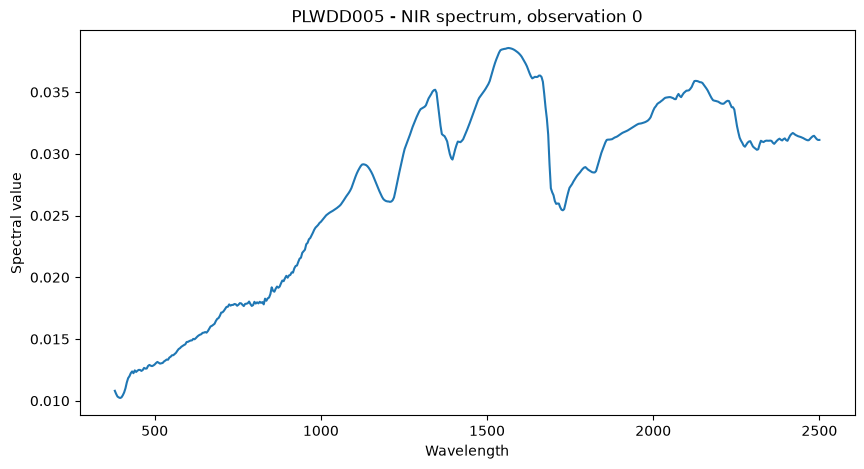

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    data.nir.wavelength,
    data.nir.spectra[0]
)

plt.xlabel("Wavelength")
plt.ylabel("Spectral value")
plt.title(f"{pilot_hole} - NIR spectrum, observation 0")

plt.show()

In [41]:
spectra = np.asarray(data.nir.spectra)

print("Spectra shape:", spectra.shape)

print("NaN values:", np.isnan(spectra).sum())

print("Minimum:", np.nanmin(spectra))
print("Maximum:", np.nanmax(spectra))
print("Mean:", np.nanmean(spectra))

Spectra shape: (405, 531)
NaN values: 0
Minimum: 0.0029995653
Maximum: 0.6664083
Mean: 0.21293812


In [42]:
# ============================================================
# STEP 4: FINISH EXTRACTION + BASIC TRANSFORMATION
# Pilot hole: PLWDD005
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Project/output directories
# ------------------------------------------------------------

pilot_hole = "PLWDD005"

processed_dir = PROJECT_ROOT / "data" / "processed" / pilot_hole
processed_dir.mkdir(parents=True, exist_ok=True)

print("Processing hole:", pilot_hole)
print("Output directory:", processed_dir)


# ------------------------------------------------------------
# 2. SAMPLE / DEPTH METADATA
# ------------------------------------------------------------

samples = data.nir.sampleheaders.copy()

# Preserve all original TSG fields.
# Add friendly fields instead of deleting/renaming raw columns.
samples["sample_index"] = np.arange(len(samples))

# D appears to contain downhole depth in this package
samples["depth_m"] = pd.to_numeric(samples["D"], errors="coerce")

# H contains hole identifier
samples["hole_id"] = samples["H"].astype(str)

samples["sensor"] = "NIR"
samples["spectrum_index"] = np.arange(len(samples))


# ------------------------------------------------------------
# 3. CLEAN SCALAR / QA DATA
# ------------------------------------------------------------

scalars = data.nir.scalars.copy()

# TSG frequently uses a very large negative float as NODATA
TSG_NODATA = -3.402823e38

# Start with an unchanged copy so string/categorical fields are preserved
scalars_clean = scalars.copy()

numeric_columns = scalars_clean.select_dtypes(
    include=[np.number]
).columns

scalars_clean[numeric_columns] = (
    scalars_clean[numeric_columns]
    .mask(scalars_clean[numeric_columns] < -1e30)
)
# Add linking fields
scalars_clean.insert(
    0,
    "sample_index",
    np.arange(len(scalars_clean))
)

scalars_clean.insert(
    1,
    "hole_id",
    pilot_hole
)


# ------------------------------------------------------------
# 4. VERIFY ROW ALIGNMENT
# ------------------------------------------------------------

nir_spectra = np.asarray(data.nir.spectra)
nir_wavelengths = np.asarray(data.nir.wavelength)

assert len(samples) == len(scalars_clean)
assert len(samples) == nir_spectra.shape[0]
assert nir_spectra.shape[1] == len(nir_wavelengths)

print("\nAlignment check:")
print("Samples:     ", len(samples))
print("Scalars:     ", len(scalars_clean))
print("Spectra:     ", nir_spectra.shape)
print("Wavelengths: ", nir_wavelengths.shape)

print("PASS - metadata, scalars and spectra are aligned.")


# ------------------------------------------------------------
# 5. IDENTIFY POTENTIAL QA / UNCERTAINTY FIELDS
# ------------------------------------------------------------

qa_keywords = [
    "error",
    "snr",
    "score",
    "mask",
    "flag",
    "quality",
    "stat",
    "valid",
    "tsa"
]

qa_columns = [
    col
    for col in scalars_clean.columns
    if any(
        keyword in str(col).lower()
        for keyword in qa_keywords
    )
]

print("\nPotential QA/QC fields found:", len(qa_columns))

for col in qa_columns:
    print("  ", col)


# ------------------------------------------------------------
# 6. CREATE SCALAR AVAILABILITY SUMMARY
# ------------------------------------------------------------

scalar_summary = pd.DataFrame({
    "field": [
        col
        for col in scalars_clean.columns
        if col not in ["sample_index", "hole_id"]
    ]
})

scalar_summary["non_missing"] = [
    scalars_clean[col].notna().sum()
    for col in scalar_summary["field"]
]

scalar_summary["total_rows"] = len(scalars_clean)

scalar_summary["availability_percent"] = (
    scalar_summary["non_missing"]
    / scalar_summary["total_rows"]
    * 100
)

scalar_summary = scalar_summary.sort_values(
    "availability_percent",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------------------
# 7. EXTRACT MINERAL / CLASS LOOKUP DICTIONARIES
# ------------------------------------------------------------

class_lookups = {}

for class_number, header in data.nir.classes.items():

    class_lookups[str(class_number)] = {
        "class_number": int(class_number),
        "name": header.name,
        "classes": {
            str(code): label
            for code, label in header.classes.items()
        }
    }


# ------------------------------------------------------------
# 8. CHECK WHICH SENSOR COMPONENTS ARE ACTUALLY AVAILABLE
# ------------------------------------------------------------

sensor_summary = {}

for sensor_name in ["nir", "tir", "mir", "cras", "lidar"]:

    component = getattr(data, sensor_name, None)

    # Some pyTSG attributes may be class/type placeholders
    # rather than actual loaded datasets.
    has_spectra = (
        component is not None
        and not isinstance(component, type)
        and hasattr(component, "spectra")
    )

    has_wavelength = (
        component is not None
        and not isinstance(component, type)
        and hasattr(component, "wavelength")
    )

    sensor_summary[sensor_name] = {
        "data_loaded": bool(
            component is not None
            and not isinstance(component, type)
        ),
        "has_spectra": bool(has_spectra),
        "has_wavelength": bool(has_wavelength)
    }

    if has_spectra:
        sensor_summary[sensor_name]["spectra_shape"] = list(
            np.shape(component.spectra)
        )

    if has_wavelength:
        sensor_summary[sensor_name]["wavelength_shape"] = list(
            np.shape(component.wavelength)
        )


# ------------------------------------------------------------
# 9. SAVE NIR SPECTRAL MATRIX
#
# IMPORTANT:
# We do NOT create one SQL row per wavelength reading.
#
# 405 x 531 = 215,055 values stay together as an array.
# PostGIS will later store only one row per observation/sample.
# ------------------------------------------------------------

spectra_path = processed_dir / f"{pilot_hole}_nir_spectra.npz"

np.savez_compressed(
    spectra_path,
    wavelengths=nir_wavelengths,
    spectra=nir_spectra
)


# ------------------------------------------------------------
# 10. SAVE CLEAN QUERYABLE TABLES
# ------------------------------------------------------------

samples_path = processed_dir / f"{pilot_hole}_samples.csv"

samples.to_csv(
    samples_path,
    index=False
)


scalars_path = processed_dir / f"{pilot_hole}_scalars.csv"

scalars_clean.to_csv(
    scalars_path,
    index=False
)


scalar_summary_path = (
    processed_dir
    / f"{pilot_hole}_scalar_summary.csv"
)

scalar_summary.to_csv(
    scalar_summary_path,
    index=False
)


# ------------------------------------------------------------
# 11. SAVE CLASS / MINERAL VOCABULARIES
# ------------------------------------------------------------

classes_path = processed_dir / f"{pilot_hole}_classes.json"

with open(
    classes_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        class_lookups,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 12. SAVE PROVENANCE
# ------------------------------------------------------------

provenance = {
    "hole_id": pilot_hole,

    "source_dataset": "PLWDD005.zip",

    "source_catalogue": "GSWA NVCL",

    "source_system": "WAMEX",

    "reference_number": 112432,

    "collar_id": 3991007,

    "parser": "pytsg",

    "nir_samples": int(len(samples)),

    "nir_wavelength_count": int(len(nir_wavelengths)),

    "nir_spectra_shape": list(nir_spectra.shape),

    # We intentionally leave this unknown until
    # confirmed from authoritative package metadata.
    "processing_level": None,

    # Collar coordinates will be added later.
    "longitude": None,
    "latitude": None,

    "sensor_summary": sensor_summary,

    "etl_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}


provenance_path = (
    processed_dir
    / f"{pilot_hole}_provenance.json"
)

with open(
    provenance_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        provenance,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 13. VERIFY FILES CAN BE READ BACK
# ------------------------------------------------------------

check_spectra = np.load(spectra_path)

assert check_spectra["spectra"].shape == nir_spectra.shape

assert (
    check_spectra["wavelengths"].shape
    == nir_wavelengths.shape
)

check_samples = pd.read_csv(samples_path)

assert len(check_samples) == len(samples)


# ------------------------------------------------------------
# 14. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("EXTRACT + BASIC TRANSFORM COMPLETE")
print("=" * 60)

print("\nHole:", pilot_hole)

print(
    "Depth range:",
    round(samples["depth_m"].min(), 3),
    "to",
    round(samples["depth_m"].max(), 3),
    "m"
)

print("\nNIR spectra:")
print("  Samples:", nir_spectra.shape[0])
print("  Wavelength bands:", nir_spectra.shape[1])

print(
    "  Total spectral values:",
    nir_spectra.size
)

print("\nDatabase rows required for spectra metadata:")
print(" ", len(samples))

print("\nNOT:")
print(" ", nir_spectra.size, "rows")

print("\nClass dictionaries:")

for key, value in class_lookups.items():
    print(
        f"  {key}: {value['name']} "
        f"({len(value['classes'])} classes)"
    )

print("\nAvailable sensor information:")

for sensor, info in sensor_summary.items():
    print(" ", sensor.upper(), ":", info)

print("\nFiles created:")

for file in processed_dir.iterdir():
    if file.is_file():
        print(" ", file.name)

print("\nRemaining extraction work:")
print("  1. Confirm actual per-sample mineral assignments")
print("  2. Confirm GSWA processing level")
print("  3. Retrieve collar longitude/latitude")

Processing hole: PLWDD005
Output directory: C:\Users\Meghana gundu\Desktop\hylogger\data\processed\PLWDD005

Alignment check:
Samples:      405
Scalars:      405
Spectra:      (405, 531)
Wavelengths:  (531,)
PASS - metadata, scalars and spectra are aligned.

Potential QA/QC fields found: 30
   Flags
   Grp1 sTSAS
   TNorm sTSAS
   Final Mask
   Error sTSAV
   Wt1 sTSAV
   Grp1 sTSAV
   Min2 sTSAS
   Unbound_Water sTSAS
   Grp2 sTSAS
   Bound_Water sTSAS
   Wt2 sTSAS
   Min3 sTSAS
   Grp3 sTSAS
   Grp2 sTSAV
   AspRat sTSAS
   CustSample
   Wt2 sTSAV
   Min2 sTSAV
   NIL_Stat sTSAS
   Min1 sTSAV
   Wt1 sTSAS
   SNR sTSAV
   NIL_Stat sTSAV
   SNR sTSAS
   Wt3 sTSAS
   CustScore
   sec_end_mask
   Error sTSAS
   Min1 sTSAS


C:\Users\Meghana gundu\AppData\Local\Temp\ipykernel_14380\486241720.py:67: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  scalars_clean.insert(
C:\Users\Meghana gundu\AppData\Local\Temp\ipykernel_14380\486241720.py:73: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  scalars_clean.insert(



EXTRACT + BASIC TRANSFORM COMPLETE

Hole: PLWDD005
Depth range: 101.55 to 103.3 m

NIR spectra:
  Samples: 405
  Wavelength bands: 531
  Total spectral values: 215055

Database rows required for spectra metadata:
  405

NOT:
  215055 rows

Class dictionaries:
  0: Domain (1 classes)
  1: S_SWIR_TSA705 Groups (17 classes)
  2: S_VNIR_TSA704 Groups (8 classes)
  3: S_SWIR_TSA705 Minerals (61 classes)
  4: Tray (1 classes)
  5: HoleID (1 classes)
  6: HyLogDiag (5 classes)
  7: S_VNIR_TSA704 Minerals (21 classes)
  8: RockMarks (0 classes)

Available sensor information:
  NIR : {'data_loaded': True, 'has_spectra': True, 'has_wavelength': True, 'spectra_shape': [405, 531], 'wavelength_shape': [531]}
  TIR : {'data_loaded': True, 'has_spectra': True, 'has_wavelength': True, 'spectra_shape': [405, 341], 'wavelength_shape': [341]}
  MIR : {'data_loaded': False, 'has_spectra': False, 'has_wavelength': False}
  CRAS : {'data_loaded': False, 'has_spectra': False, 'has_wavelength': False}
  LIDA

In [43]:
# ============================================================
# STEP 5: DECODE MINERAL CLASSES + QA STATES + LEVEL INFERENCE
# ============================================================

import re
import json
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Turn pyTSG band headers into a DataFrame
# ------------------------------------------------------------

bandheaders_df = pd.DataFrame(
    data.nir.bandheaders,
    columns=["band", "name", "class_number", "flag"]
)

print("Band headers:", len(bandheaders_df))

# Only bands linked to a TSG class dictionary
class_bands = bandheaders_df[
    bandheaders_df["class_number"] >= 0
].copy()

print("Class-linked bands:", len(class_bands))

display(
    class_bands[
        ["band", "name", "class_number", "flag"]
    ]
)


# ------------------------------------------------------------
# 2. Decode per-sample class assignments
# ------------------------------------------------------------

decoded_classes = pd.DataFrame({
    "sample_index": np.arange(len(samples)),
    "hole_id": pilot_hole,
    "depth_m": samples["depth_m"].values
})

decoded_products = []

for _, row in class_bands.iterrows():

    band_name = row["name"]
    class_number = int(row["class_number"])

    # pyTSG stores the lookup dictionary here
    if class_number not in data.nir.classes:
        continue

    class_lookup = data.nir.classes[class_number]

    # The actual per-sample codes should appear in scalars
    # under the corresponding band name.
    if band_name not in scalars_clean.columns:
        continue

    codes = pd.to_numeric(
        scalars_clean[band_name],
        errors="coerce"
    )

    def decode_value(value):

        if pd.isna(value):
            return None

        code = int(value)

        return class_lookup.classes.get(
            code,
            None
        )

    labels = codes.apply(decode_value)

    # Create safe SQL/CSV-friendly name
    safe_name = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        band_name
    ).strip("_").lower()

    decoded_classes[
        f"{safe_name}_code"
    ] = codes

    decoded_classes[
        f"{safe_name}_label"
    ] = labels

    decoded_products.append({
        "band_name": band_name,
        "class_number": class_number,
        "lookup_name": class_lookup.name,
        "decoded_count": int(labels.notna().sum())
    })


decoded_summary = pd.DataFrame(decoded_products)

print("\nDecoded class products:")
display(decoded_summary)


# ------------------------------------------------------------
# 3. Find mineral products automatically
# ------------------------------------------------------------

mineral_label_columns = [
    c for c in decoded_classes.columns
    if "mineral" in c.lower()
    and c.endswith("_label")
]

print("\nMineral label columns found:")

for c in mineral_label_columns:
    print(" ", c)


# ------------------------------------------------------------
# 4. Pick SWIR and VNIR mineral classifications
# ------------------------------------------------------------

swir_candidates = [
    c for c in mineral_label_columns
    if "swir" in c.lower()
]

vnir_candidates = [
    c for c in mineral_label_columns
    if "vnir" in c.lower()
]


if swir_candidates:
    decoded_classes[
        "swir_mineral"
    ] = decoded_classes[
        swir_candidates[0]
    ]

if vnir_candidates:
    decoded_classes[
        "vnir_mineral"
    ] = decoded_classes[
        vnir_candidates[0]
    ]


print("\nExample decoded minerals:")

display(
    decoded_classes[
        [
            c for c in [
                "sample_index",
                "hole_id",
                "depth_m",
                "swir_mineral",
                "vnir_mineral"
            ]
            if c in decoded_classes.columns
        ]
    ].head(20)
)


# ------------------------------------------------------------
# 5. Create an explicit QA / uncertainty state
# ------------------------------------------------------------

# These are not geological minerals.
# They are TSG validity / uncertainty states.
uncertain_states = {
    "Aspectral",
    "NotInLibrary",
    "Dark",
    "Noisy",
    "HighError",
    "MaskedOff",
    "INVALID",
    "NOTAROK"
}


def quality_from_label(label):

    if pd.isna(label):
        return "missing"

    if label in uncertain_states:
        return "uncertain_or_invalid"

    return "interpreted"


# Prefer SWIR mineral result for the basic pilot view
if "swir_mineral" in decoded_classes.columns:

    decoded_classes[
        "mineral_primary"
    ] = decoded_classes[
        "swir_mineral"
    ]

elif "vnir_mineral" in decoded_classes.columns:

    decoded_classes[
        "mineral_primary"
    ] = decoded_classes[
        "vnir_mineral"
    ]

else:

    decoded_classes[
        "mineral_primary"
    ] = None


decoded_classes[
    "quality_state"
] = decoded_classes[
    "mineral_primary"
].apply(quality_from_label)


print("\nQuality-state counts:")

print(
    decoded_classes[
        "quality_state"
    ].value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 6. Add useful QA flags from scalar fields
# ------------------------------------------------------------

qa_fields_available = [
    c for c in scalars_clean.columns
    if any(
        word in str(c).lower()
        for word in [
            "error",
            "snr",
            "mask",
            "score",
            "flag"
        ]
    )
]

print("\nQA-related scalar fields retained:")

for field in qa_fields_available:
    print(" ", field)


# ------------------------------------------------------------
# 7. Infer processing level conservatively
# ------------------------------------------------------------

all_names = (
    list(scalars_clean.columns)
    +
    [x.name for x in data.nir.classes.values()]
)

all_names_lower = [
    str(x).lower()
    for x in all_names
]


has_system_tsa = any(
    ("s_" in x and "tsa" in x)
    or "stsas" in x
    or "stsav" in x
    or "stsat" in x
    for x in all_names_lower
)

has_user_tsa = any(
    ("u_" in x and "tsa" in x)
    or "utsas" in x
    or "utsav" in x
    or "utsat" in x
    for x in all_names_lower
)


if has_user_tsa:

    processing_level_inferred = "Level 2 candidate"

    processing_level_reason = (
        "User-constrained/refined TSA products detected."
    )

elif has_system_tsa:

    processing_level_inferred = "Level 1 candidate"

    processing_level_reason = (
        "Automated/system TSA products detected; "
        "no user-constrained TSA product detected."
    )

else:

    processing_level_inferred = "Unknown"

    processing_level_reason = (
        "No reliable TSA naming evidence found."
    )


print("\nProcessing-level inference:")
print(processing_level_inferred)
print(processing_level_reason)

print(
    "\nNOTE: this is recorded as an inference, "
    "not authoritative GSWA metadata."
)


# ------------------------------------------------------------
# 8. Build our final per-sample ETL table
# ------------------------------------------------------------

observation_table = samples[
    [
        "sample_index",
        "depth_m",
        "hole_id"
    ]
].copy()

observation_table[
    "sensor"
] = "NIR"

observation_table[
    "spectrum_index"
] = np.arange(
    len(observation_table)
)


# Add decoded mineral information
for col in [
    "swir_mineral",
    "vnir_mineral",
    "mineral_primary",
    "quality_state"
]:

    if col in decoded_classes.columns:

        observation_table[
            col
        ] = decoded_classes[
            col
        ].values


observation_table[
    "processing_level_inferred"
] = processing_level_inferred


# ------------------------------------------------------------
# 9. Save transformed mineral/class outputs
# ------------------------------------------------------------

decoded_path = (
    processed_dir
    / f"{pilot_hole}_decoded_classes.csv"
)

decoded_classes.to_csv(
    decoded_path,
    index=False
)


observation_path = (
    processed_dir
    / f"{pilot_hole}_observations.csv"
)

observation_table.to_csv(
    observation_path,
    index=False
)


bandheaders_path = (
    processed_dir
    / f"{pilot_hole}_bandheaders.csv"
)

bandheaders_df.to_csv(
    bandheaders_path,
    index=False
)


# ------------------------------------------------------------
# 10. Update provenance JSON
# ------------------------------------------------------------

with open(
    provenance_path,
    "r",
    encoding="utf-8"
) as f:

    provenance = json.load(f)


provenance[
    "processing_level_inferred"
] = processing_level_inferred

provenance[
    "processing_level_inference_reason"
] = processing_level_reason

provenance[
    "processing_level_authoritative"
] = None

provenance[
    "mineral_products_decoded"
] = mineral_label_columns

provenance[
    "qa_fields_retained"
] = qa_fields_available


with open(
    provenance_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        provenance,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 11. FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("MINERAL + QA TRANSFORMATION COMPLETE")
print("=" * 65)

print("\nRows:", len(observation_table))

print("\nDepth range:")
print(
    observation_table["depth_m"].min(),
    "to",
    observation_table["depth_m"].max()
)

print("\nMineral columns:")

for c in [
    "swir_mineral",
    "vnir_mineral",
    "mineral_primary"
]:

    if c in observation_table.columns:

        print(
            "\n",
            c
        )

        print(
            observation_table[c]
            .value_counts(
                dropna=False
            )
            .head(15)
        )


print("\nQuality states:")

print(
    observation_table[
        "quality_state"
    ].value_counts(
        dropna=False
    )
)


print(
    "\nProcessing level:",
    processing_level_inferred
)


print("\nFiles created:")

print(decoded_path.name)
print(observation_path.name)
print(bandheaders_path.name)

print("\nStill missing:")
print("1. Authoritative processing-level metadata")
print("2. Collar longitude / latitude")

Band headers: 126
Class-linked bands: 19


,band,name,class_number,flag
79,81,RelRange,1300.0,11
81,83,Domain,0.0,2
82,84,Grp1 sTSAS,1.0,2
90,92,Grp1 sTSAV,2.0,2
91,93,Min2 sTSAS,3.0,2
92,94,Tray,4.0,2
94,96,Grp2 sTSAS,1.0,2
96,98,HoleID,5.0,2
99,101,HyLogDiag,6.0,2
100,102,Min3 sTSAS,3.0,2



Decoded class products:


,band_name,class_number,lookup_name,decoded_count
0,Domain,0,Domain,405
1,Grp1 sTSAS,1,S_SWIR_TSA705 Groups,0
2,Grp1 sTSAV,2,S_VNIR_TSA704 Groups,0
3,Min2 sTSAS,3,S_SWIR_TSA705 Minerals,0
4,Tray,4,Tray,0
5,Grp2 sTSAS,1,S_SWIR_TSA705 Groups,0
6,HoleID,5,HoleID,0
7,HyLogDiag,6,HyLogDiag,0
8,Min3 sTSAS,3,S_SWIR_TSA705 Minerals,0
9,Grp3 sTSAS,1,S_SWIR_TSA705 Groups,0



Mineral label columns found:

Example decoded minerals:


,sample_index,hole_id,depth_m
0,0,PLWDD005,101.550007
1,1,PLWDD005,101.550007
2,2,PLWDD005,101.550006
3,3,PLWDD005,101.550006
4,4,PLWDD005,101.550006
5,5,PLWDD005,101.550006
6,6,PLWDD005,101.550005
7,7,PLWDD005,101.550005
8,8,PLWDD005,101.550005
9,9,PLWDD005,101.550005



Quality-state counts:
quality_state
missing    405
Name: count, dtype: int64

QA-related scalar fields retained:
  Flags
  Final Mask
  Error sTSAV
  SNR sTSAV
  SNR sTSAS
  CustScore
  sec_end_mask
  Error sTSAS

Processing-level inference:
Level 1 candidate
Automated/system TSA products detected; no user-constrained TSA product detected.

NOTE: this is recorded as an inference, not authoritative GSWA metadata.

MINERAL + QA TRANSFORMATION COMPLETE

Rows: 405

Depth range:
101.550004 to 103.300009

Mineral columns:

 mineral_primary
mineral_primary
None    405
Name: count, dtype: int64

Quality states:
quality_state
missing    405
Name: count, dtype: int64

Processing level: Level 1 candidate

Files created:
PLWDD005_decoded_classes.csv
PLWDD005_observations.csv
PLWDD005_bandheaders.csv

Still missing:
1. Authoritative processing-level metadata
2. Collar longitude / latitude


In [132]:
# ============================================================
# STEP 5 FINAL FIX:
# USE THE CLASS VALUES ALREADY DECODED BY pyTSG
# ============================================================

import numpy as np
import pandas as pd
import json

# ------------------------------------------------------------
# 1. Inspect original pyTSG class fields WITHOUT converting
#    them to numeric
# ------------------------------------------------------------

class_fields = [
    "Domain",
    "Grp1 sTSAS",
    "Grp2 sTSAS",
    "Grp3 sTSAS",
    "Min1 sTSAS",
    "Min2 sTSAS",
    "Min3 sTSAS",
    "Grp1 sTSAV",
    "Grp2 sTSAV",
    "Min1 sTSAV",
    "Min2 sTSAV",
    "HyLogDiag",
    "Tray",
    "HoleID"
]

print("=" * 70)
print("RAW pyTSG CLASS FIELD INSPECTION")
print("=" * 70)

for field in class_fields:

    if field not in data.nir.scalars.columns:
        continue

    series = data.nir.scalars[field]

    print("\nFIELD:", field)
    print("dtype:", series.dtype)

    print(
        series.value_counts(
            dropna=False
        ).head(15)
    )


# ------------------------------------------------------------
# 2. Build mineral table DIRECTLY from pyTSG output
# ------------------------------------------------------------

mineral_table = pd.DataFrame({
    "sample_index": np.arange(len(samples)),
    "hole_id": samples["hole_id"].values,
    "depth_m": samples["depth_m"].values
})


# Copy class fields exactly as pyTSG provides them
for field in class_fields:

    if field in data.nir.scalars.columns:

        safe_name = (
            field.lower()
            .replace(" ", "_")
            .replace("/", "_")
        )

        mineral_table[safe_name] = (
            data.nir.scalars[field]
            .reset_index(drop=True)
        )


# ------------------------------------------------------------
# 3. Choose primary mineral classifications
#
# sTSAS = system SWIR TSA
# sTSAV = system VNIR TSA
#
# Min1 is the first / primary mineral result.
# ------------------------------------------------------------

if "min1_stsas" in mineral_table.columns:

    mineral_table[
        "swir_mineral_primary"
    ] = mineral_table[
        "min1_stsas"
    ]

else:

    mineral_table[
        "swir_mineral_primary"
    ] = None


if "min1_stsav" in mineral_table.columns:

    mineral_table[
        "vnir_mineral_primary"
    ] = mineral_table[
        "min1_stsav"
    ]

else:

    mineral_table[
        "vnir_mineral_primary"
    ] = None


# ------------------------------------------------------------
# 4. Define uncertainty / invalid states
# ------------------------------------------------------------

uncertain_states = {
    "Aspectral",
    "NotInLibrary",
    "Dark",
    "Noisy",
    "HighError",
    "MaskedOff",
    "INVALID",
    "NOTAROK"
}


def classify_quality(value):

    if pd.isna(value):
        return "missing"

    value = str(value).strip()

    if value in uncertain_states:
        return "uncertain_or_invalid"

    return "interpreted"


mineral_table[
    "swir_quality_state"
] = mineral_table[
    "swir_mineral_primary"
].apply(classify_quality)


mineral_table[
    "vnir_quality_state"
] = mineral_table[
    "vnir_mineral_primary"
].apply(classify_quality)


# ------------------------------------------------------------
# 5. Add numeric QA/QC fields separately
#
# These remain numeric and should have TSG NODATA converted
# to proper NaN.
# ------------------------------------------------------------

qa_numeric_fields = [
    "Final Mask",
    "Error sTSAV",
    "SNR sTSAV",
    "SNR sTSAS",
    "CustScore",
    "sec_end_mask",
    "Error sTSAS",
    "NIL_Stat sTSAS",
    "NIL_Stat sTSAV"
]


for field in qa_numeric_fields:

    if field not in data.nir.scalars.columns:
        continue

    values = pd.to_numeric(
        data.nir.scalars[field],
        errors="coerce"
    )

    values = values.mask(
        values < -1e30
    )

    safe_name = (
        field.lower()
        .replace(" ", "_")
        .replace("/", "_")
    )

    mineral_table[safe_name] = values.values


# ------------------------------------------------------------
# 6. Processing-level metadata
# ------------------------------------------------------------

mineral_table[
    "processing_level"
] = 1

mineral_table[
    "processing_level_status"
] = "inferred"

mineral_table[
    "processing_level_basis"
] = "system_TSA_products_sTSAS_sTSAV"


# ------------------------------------------------------------
# 7. Display useful result
# ------------------------------------------------------------

display_columns = [
    "sample_index",
    "hole_id",
    "depth_m",
    "swir_mineral_primary",
    "swir_quality_state",
    "vnir_mineral_primary",
    "vnir_quality_state"
]

display(
    mineral_table[
        display_columns
    ].head(30)
)


print("\n" + "=" * 70)
print("SWIR PRIMARY MINERAL COUNTS")
print("=" * 70)

print(
    mineral_table[
        "swir_mineral_primary"
    ].value_counts(
        dropna=False
    ).head(30)
)


print("\n" + "=" * 70)
print("VNIR PRIMARY MINERAL COUNTS")
print("=" * 70)

print(
    mineral_table[
        "vnir_mineral_primary"
    ].value_counts(
        dropna=False
    ).head(30)
)


print("\n" + "=" * 70)
print("SWIR QUALITY STATES")
print("=" * 70)

print(
    mineral_table[
        "swir_quality_state"
    ].value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 8. Save corrected mineral table
# ------------------------------------------------------------

mineral_output_path = (
    processed_dir
    / f"{pilot_hole}_minerals_final.csv"
)

mineral_table.to_csv(
    mineral_output_path,
    index=False
)


# ------------------------------------------------------------
# 9. Update provenance
# ------------------------------------------------------------

with open(
    provenance_path,
    "r",
    encoding="utf-8"
) as f:

    provenance = json.load(f)


provenance["processing_level"] = 1
provenance["processing_level_status"] = "inferred"

provenance[
    "processing_level_basis"
] = "system_TSA_products_sTSAS_sTSAV"

provenance[
    "mineral_table"
] = mineral_output_path.name


with open(
    provenance_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        provenance,
        f,
        indent=2
    )


print("\nSaved:")
print(mineral_output_path)

print("\nMineral transformation finished.")

RAW pyTSG CLASS FIELD INSPECTION

FIELD: Domain
dtype: float32
Domain
0.0    405
Name: count, dtype: int64

FIELD: Grp1 sTSAS
dtype: str
Grp1 sTSAS
            320
KAOLIN       84
SMECTITE      1
Name: count, dtype: int64

FIELD: Grp2 sTSAS
dtype: str
Grp2 sTSAS
              361
KAOLIN         16
WHITE-MICA     10
SMECTITE       10
SULPHATE        7
OTHER-ALOH      1
Name: count, dtype: int64

FIELD: Grp3 sTSAS
dtype: str
Grp3 sTSAS
            403
SULPHATE      2
Name: count, dtype: int64

FIELD: Min1 sTSAS
dtype: str
Min1 sTSAS
                   320
Kaolinite-WX        47
Kaolinite-PX        22
Dickite             15
Montmorillonite      1
Name: count, dtype: int64

FIELD: Min2 sTSAS
dtype: str
Min2 sTSAS
                   361
Dickite             14
Montmorillonite     10
Muscovite            9
Gypsum               7
Kaolinite-WX         2
Phengite             1
Diaspore             1
Name: count, dtype: int64

FIELD: Min3 sTSAS
dtype: str
Min3 sTSAS
          403
Gypsum      2
Na

,sample_index,hole_id,depth_m,swir_mineral_primary,swir_quality_state,vnir_mineral_primary,vnir_quality_state
0,0,PLWDD005,101.550007,,interpreted,,interpreted
1,1,PLWDD005,101.550007,,interpreted,,interpreted
2,2,PLWDD005,101.550006,,interpreted,,interpreted
3,3,PLWDD005,101.550006,,interpreted,,interpreted
4,4,PLWDD005,101.550006,,interpreted,,interpreted
5,5,PLWDD005,101.550006,,interpreted,,interpreted
6,6,PLWDD005,101.550005,,interpreted,,interpreted
7,7,PLWDD005,101.550005,,interpreted,,interpreted
8,8,PLWDD005,101.550005,,interpreted,,interpreted
9,9,PLWDD005,101.550005,,interpreted,,interpreted



SWIR PRIMARY MINERAL COUNTS
swir_mineral_primary
                   320
Kaolinite-WX        47
Kaolinite-PX        22
Dickite             15
Montmorillonite      1
Name: count, dtype: int64

VNIR PRIMARY MINERAL COUNTS
vnir_mineral_primary
            402
Goethite      3
Name: count, dtype: int64

SWIR QUALITY STATES
swir_quality_state
interpreted    405
Name: count, dtype: int64

Saved:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\PLWDD005\PLWDD005_minerals_final.csv

Mineral transformation finished.


In [133]:
# ============================================================
# STEP 6: FINALISE PILOT EXTRACTION
# Fix missing mineral states + add provisional collar metadata
# ============================================================

import json
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. FIX MINERAL QUALITY LOGIC
# ------------------------------------------------------------

uncertain_states = {
    "Aspectral",
    "NotInLibrary",
    "Dark",
    "Noisy",
    "HighError",
    "MaskedOff",
    "INVALID",
    "NOTAROK"
}


def classify_quality(value):

    # True missing value
    if pd.isna(value):
        return "missing"

    value = str(value).strip()

    # pyTSG class columns use blank strings where
    # no mineral interpretation is present
    if value == "":
        return "missing"

    # Explicit TSG uncertainty / invalid classes
    if value in uncertain_states:
        return "uncertain_or_invalid"

    return "interpreted"


mineral_table["swir_quality_state"] = (
    mineral_table["swir_mineral_primary"]
    .apply(classify_quality)
)

mineral_table["vnir_quality_state"] = (
    mineral_table["vnir_mineral_primary"]
    .apply(classify_quality)
)


# ------------------------------------------------------------
# 2. NORMALISE EMPTY MINERAL STRINGS TO NaN
# ------------------------------------------------------------

for col in [
    "swir_mineral_primary",
    "vnir_mineral_primary"
]:

    mineral_table[col] = (
        mineral_table[col]
        .replace(r"^\s*$", np.nan, regex=True)
    )


# ------------------------------------------------------------
# 3. ADD DATASET IDENTIFIERS
# ------------------------------------------------------------

mineral_table["dataset"] = "PLWDD005.zip"
mineral_table["source_system"] = "WAMEX"

mineral_table["reference_number"] = 112432
mineral_table["collar_id"] = 3991007


# ------------------------------------------------------------
# 4. PROCESSING LEVEL
#
# GeoView officially has a PROC_LEVEL field.
#
# For this package we currently have strong Level-1 evidence:
# system TSA products (sTSAS / sTSAV) and automated mineralogy.
#
# Until the exact GeoView record is retrieved, preserve the
# difference between inferred and authoritative values.
# ------------------------------------------------------------

mineral_table["processing_level"] = 1

mineral_table[
    "processing_level_status"
] = "inferred"

mineral_table[
    "processing_level_basis"
] = "system TSA products (sTSAS/sTSAV)"


# ------------------------------------------------------------
# 5. PROVISIONAL COLLAR COORDINATES
#
# Public drillhole report:
# MGA94 / Zone 51
#
# These are NOT yet marked as authoritative GSWA GeoView
# coordinates.
# ------------------------------------------------------------

collar = {
    "collar_id": 3991007,
    "hole_id": "PLWDD005",

    "easting": 497511.24,
    "northing": 6986643.05,
    "rl_m": 447.73,

    "crs": "MGA94 / MGA Zone 51",
    "epsg": 28351,

    "coordinate_status": "provisional",
    "coordinate_source": "public drillhole report"
}


# ------------------------------------------------------------
# 6. CREATE FINAL HOLE-LEVEL METADATA RECORD
# ------------------------------------------------------------

hole_metadata = pd.DataFrame([{

    "hole_id": pilot_hole,

    "dataset": "PLWDD005.zip",

    "source_system": "WAMEX",

    "reference_number": 112432,

    "collar_id": 3991007,

    "processing_level": 1,

    "processing_level_status": "inferred",

    "scan_start_m": float(
        samples["depth_m"].min()
    ),

    "scan_end_m": float(
        samples["depth_m"].max()
    ),

    "nir_sample_count": int(
        len(samples)
    ),

    "nir_wavelength_count": int(
        len(nir_wavelengths)
    ),

    "easting": collar["easting"],

    "northing": collar["northing"],

    "rl_m": collar["rl_m"],

    "source_epsg": collar["epsg"],

    "coordinate_status": collar[
        "coordinate_status"
    ]
}])


# ------------------------------------------------------------
# 7. SAVE CORRECTED FINAL OUTPUTS
# ------------------------------------------------------------

mineral_output_path = (
    processed_dir
    / f"{pilot_hole}_minerals_final.csv"
)

mineral_table.to_csv(
    mineral_output_path,
    index=False
)


hole_metadata_path = (
    processed_dir
    / f"{pilot_hole}_hole_metadata.csv"
)

hole_metadata.to_csv(
    hole_metadata_path,
    index=False
)


# ------------------------------------------------------------
# 8. UPDATE PROVENANCE
# ------------------------------------------------------------

with open(
    provenance_path,
    "r",
    encoding="utf-8"
) as f:

    provenance = json.load(f)


provenance.update({

    "processing_level": 1,

    "processing_level_status": "inferred",

    "processing_level_basis":
        "system TSA products (sTSAS/sTSAV)",

    "collar": collar,

    "minerals_output":
        mineral_output_path.name,

    "hole_metadata_output":
        hole_metadata_path.name
})


with open(
    provenance_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        provenance,
        f,
        indent=2
    )


# ------------------------------------------------------------
# 9. VALIDATION
# ------------------------------------------------------------

assert len(mineral_table) == len(samples)

assert mineral_table["sample_index"].is_unique

assert (
    mineral_table["depth_m"]
    .notna()
    .all()
)


print("=" * 70)
print("PILOT EXTRACTION / TRANSFORMATION SUMMARY")
print("=" * 70)

print("\nHole:")
print(pilot_hole)

print("\nSamples:")
print(len(mineral_table))

print("\nSWIR minerals:")
print(
    mineral_table[
        "swir_mineral_primary"
    ].value_counts(
        dropna=False
    )
)

print("\nSWIR quality:")
print(
    mineral_table[
        "swir_quality_state"
    ].value_counts(
        dropna=False
    )
)

print("\nVNIR minerals:")
print(
    mineral_table[
        "vnir_mineral_primary"
    ].value_counts(
        dropna=False
    )
)

print("\nProcessing level:")
print(
    hole_metadata[
        [
            "processing_level",
            "processing_level_status"
        ]
    ]
)

print("\nCollar:")
print(
    hole_metadata[
        [
            "easting",
            "northing",
            "rl_m",
            "source_epsg",
            "coordinate_status"
        ]
    ]
)

print("\nPASS - pilot data ready for loading.")

PILOT EXTRACTION / TRANSFORMATION SUMMARY

Hole:
PLWDD005

Samples:
405

SWIR minerals:
swir_mineral_primary
NaN                320
Kaolinite-WX        47
Kaolinite-PX        22
Dickite             15
Montmorillonite      1
Name: count, dtype: int64

SWIR quality:
swir_quality_state
missing        320
interpreted     85
Name: count, dtype: int64

VNIR minerals:
vnir_mineral_primary
NaN         402
Goethite      3
Name: count, dtype: int64

Processing level:
   processing_level processing_level_status
0                 1                inferred

Collar:
     easting    northing    rl_m  source_epsg coordinate_status
0  497511.24  6986643.05  447.73        28351       provisional

PASS - pilot data ready for loading.


In [44]:
# ============================================================
# PHASE 2 — MULTI-HOLE HYLOGGER ETL PIPELINE
#
# What this does:
# 1. Takes holes from NVCL catalogue
# 2. Downloads ZIP automatically
# 3. Extracts ZIP automatically
# 4. Finds TSG package
# 5. Parses with pyTSG
# 6. Extracts NIR spectra
# 7. Extracts depths
# 8. Extracts SWIR/VNIR minerals
# 9. Preserves QA/QC
# 10. Stores spectra compactly as NPZ
# 11. Creates hole metadata ready for PostGIS
#
# Distance preparation:
# - collar_id is retained
# - easting/northing fields are created
# - coordinate status is tracked
# ============================================================

from pathlib import Path
from pytsg import parse_tsg

import pandas as pd
import numpy as np
import requests
import zipfile
import json
import re
import traceback
from datetime import datetime, timezone


# ============================================================
# CONFIGURATION
# ============================================================

BASE_DOWNLOAD_URL = (
    "https://thredds.nci.org.au/thredds/fileServer/rs07/WA"
)

RAW_ROOT = PROJECT_ROOT / "data" / "raw"
PROCESSED_ROOT = PROJECT_ROOT / "data" / "processed"

RAW_ROOT.mkdir(parents=True, exist_ok=True)
PROCESSED_ROOT.mkdir(parents=True, exist_ok=True)

TSG_NODATA_LIMIT = -1e30


# ============================================================
# HELPER — DOWNLOAD
# ============================================================

def download_file(url, destination):

    destination = Path(destination)

    # Do not re-download an existing file
    if destination.exists():
        print("  ZIP already exists.")
        return

    print("  Downloading...")

    with requests.get(
        url,
        stream=True,
        timeout=180
    ) as response:

        response.raise_for_status()

        with open(destination, "wb") as f:

            for chunk in response.iter_content(
                chunk_size=1024 * 1024
            ):

                if chunk:
                    f.write(chunk)

    print("  Download complete.")


# ============================================================
# HELPER — CLASS / MINERAL QUALITY
# ============================================================

UNCERTAIN_STATES = {
    "Aspectral",
    "NotInLibrary",
    "Dark",
    "Noisy",
    "HighError",
    "MaskedOff",
    "INVALID",
    "NOTAROK"
}


def classify_quality(value):

    if pd.isna(value):
        return "missing"

    value = str(value).strip()

    if value == "":
        return "missing"

    if value in UNCERTAIN_STATES:
        return "uncertain_or_invalid"

    return "interpreted"


# ============================================================
# MAIN FUNCTION
# ============================================================

def process_hole(catalog_row):

    hole_id = str(
        catalog_row["hole_name"]
    ).strip()

    dataset = str(
        catalog_row["dataset"]
    ).strip()

    print("\n")
    print("=" * 70)
    print("PROCESSING:", hole_id)
    print("=" * 70)

    # --------------------------------------------------------
    # Catalogue metadata
    # --------------------------------------------------------

    reference_number = catalog_row.get(
        "reference_number",
        None
    )

    collar_id = catalog_row.get(
        "collar_id",
        None
    )

    source = catalog_row.get(
        "source",
        None
    )

    size_mb = catalog_row.get(
        "size_mb",
        None
    )


    # --------------------------------------------------------
    # Directories
    # --------------------------------------------------------

    raw_dir = RAW_ROOT / hole_id

    processed_dir = (
        PROCESSED_ROOT / hole_id
    )

    raw_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    processed_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    zip_path = raw_dir / dataset

    extract_dir = (
        raw_dir / "extracted"
    )


    try:

        # ====================================================
        # EXTRACT — DOWNLOAD ZIP
        # ====================================================

        download_url = (
            f"{BASE_DOWNLOAD_URL}/{dataset}"
        )

        download_file(
            download_url,
            zip_path
        )


        # ====================================================
        # EXTRACT — VALIDATE ZIP
        # ====================================================

        if not zipfile.is_zipfile(
            zip_path
        ):
            raise ValueError(
                f"{dataset} is not a valid ZIP"
            )


        # ====================================================
        # EXTRACT — UNZIP
        # ====================================================

        if not extract_dir.exists():

            extract_dir.mkdir(
                parents=True,
                exist_ok=True
            )

        # Avoid repeatedly extracting
        if not any(
            extract_dir.iterdir()
        ):

            print("  Extracting ZIP...")

            with zipfile.ZipFile(
                zip_path,
                "r"
            ) as z:

                z.extractall(
                    extract_dir
                )


        # ====================================================
        # FIND PRIMARY TSG PACKAGE
        # ====================================================

        primary_tsg_files = list(
            extract_dir.rglob(
                "*_tsg.tsg"
            )
        )

        if len(
            primary_tsg_files
        ) == 0:

            raise FileNotFoundError(
                "No *_tsg.tsg file found"
            )

        primary_tsg = (
            primary_tsg_files[0]
        )

        package_dir = (
            primary_tsg.parent
        )

        print(
            "  TSG:",
            primary_tsg.name
        )


        # ====================================================
        # PARSE WITH pyTSG
        # ====================================================

        package = (
            parse_tsg.read_package(
                str(package_dir)
            )
        )

        nir = getattr(
            package,
            "nir",
            None
        )

        if (
            nir is None
            or isinstance(nir, type)
            or not hasattr(
                nir,
                "spectra"
            )
        ):

            raise ValueError(
                "No usable NIR data"
            )


        # ====================================================
        # EXTRACT SPECTRA
        # ====================================================

        spectra = np.asarray(
            nir.spectra
        )

        wavelengths = np.asarray(
            nir.wavelength
        )

        print(
            "  Spectra:",
            spectra.shape
        )


        # ====================================================
        # EXTRACT SAMPLE METADATA
        # ====================================================

        samples = (
            nir.sampleheaders.copy()
        )

        samples[
            "sample_index"
        ] = np.arange(
            len(samples)
        )

        samples[
            "depth_m"
        ] = pd.to_numeric(
            samples["D"],
            errors="coerce"
        )

        samples[
            "hole_id"
        ] = hole_id

        samples[
            "spectrum_index"
        ] = np.arange(
            len(samples)
        )


        # ====================================================
        # EXTRACT SCALARS / QA
        # ====================================================

        scalars = (
            nir.scalars.copy()
        )

        # Important:
        # only mask numeric NODATA values;
        # do NOT destroy categorical mineral strings.

        numeric_scalars = (
            scalars.select_dtypes(
                include=[np.number]
            ).copy()
        )

        numeric_scalars = (
            numeric_scalars.mask(
                numeric_scalars
                < TSG_NODATA_LIMIT
            )
        )

        # ============================================================
        # AUTO-DISCOVER ALL PROCESSED HOLES FOR IMAGE INDEXING
        # ============================================================

        image_records = []

        processed_holes = [
            folder.name
            for folder in PROCESSED_ROOT.iterdir()
            if folder.is_dir()
        ]

        print("Processed holes found:", len(processed_holes))

        for hole_id in processed_holes:

            hole_raw_dir = RAW_ROOT / hole_id

            if not hole_raw_dir.exists():
                continue

            image_files = [
                p for p in hole_raw_dir.rglob("*")
                if p.is_file()
                and p.suffix.lower() in {
                    ".jpg", ".jpeg", ".png", ".tif", ".tiff"
                }
            ]

            for path in image_files:

                filename = path.name.lower()

                if "mosaic" in filename:
                    image_type = "tsg_mosaic"

                elif re.search(r"_\d+\.", filename):
                    image_type = "core_tray"

                else:
                    image_type = "other"

                image_records.append({
                    "hole_id": hole_id,
                    "image_type": image_type,
                    "filename": path.name,
                    "local_path": str(path),
                    "object_key": f"images/{hole_id}/{path.name}"
                })

        image_index = pd.DataFrame(image_records)

        print("Images indexed:", len(image_index))

        display(image_index.head(20))
        # ====================================================
        # EXTRACT MINERAL CLASSIFICATIONS
        # ====================================================

        minerals = pd.DataFrame({
            "sample_index":
                np.arange(len(samples)),

            "hole_id":
                hole_id,

            "depth_m":
                samples[
                    "depth_m"
                ].values,

            "spectrum_index":
                np.arange(len(samples))
        })


        # SWIR primary mineral
        if (
            "Min1 sTSAS"
            in scalars.columns
        ):

            minerals[
                "swir_mineral"
            ] = (
                scalars[
                    "Min1 sTSAS"
                ]
                .astype(str)
                .str.strip()
                .replace(
                    "",
                    np.nan
                )
            )

        else:

            minerals[
                "swir_mineral"
            ] = np.nan


        # VNIR primary mineral
        if (
            "Min1 sTSAV"
            in scalars.columns
        ):

            minerals[
                "vnir_mineral"
            ] = (
                scalars[
                    "Min1 sTSAV"
                ]
                .astype(str)
                .str.strip()
                .replace(
                    "",
                    np.nan
                )
            )

        else:

            minerals[
                "vnir_mineral"
            ] = np.nan


        minerals[
            "swir_quality"
        ] = minerals[
            "swir_mineral"
        ].apply(
            classify_quality
        )

        minerals[
            "vnir_quality"
        ] = minerals[
            "vnir_mineral"
        ].apply(
            classify_quality
        )


        # ====================================================
        # RETAIN IMPORTANT QA FIELDS
        # ====================================================

        qa_fields = [
            "Final Mask",
            "Error sTSAS",
            "Error sTSAV",
            "SNR sTSAS",
            "SNR sTSAV",
            "NIL_Stat sTSAS",
            "NIL_Stat sTSAV",
            "CustScore"
        ]


        for field in qa_fields:

            if (
                field
                not in scalars.columns
            ):
                continue

            values = pd.to_numeric(
                scalars[field],
                errors="coerce"
            )

            values = values.mask(
                values
                < TSG_NODATA_LIMIT
            )

            safe_name = (
                field
                .lower()
                .replace(" ", "_")
            )

            minerals[
                safe_name
            ] = values.values


        # ====================================================
        # PROCESSING LEVEL
        # ====================================================

        field_names = [
            str(x).lower()
            for x in scalars.columns
        ]

        has_system_tsa = any(
            "stsas" in x
            or "stsav" in x
            for x in field_names
        )

        has_user_tsa = any(
            "utsas" in x
            or "utsav" in x
            for x in field_names
        )


        if has_user_tsa:

            processing_level = 2
            processing_status = (
                "inferred"
            )

        elif has_system_tsa:

            processing_level = 1
            processing_status = (
                "inferred"
            )

        else:

            processing_level = None
            processing_status = (
                "unknown"
            )


        # ====================================================
        # SAVE SPECTRA
        #
        # This avoids SQL row explosion.
        # ====================================================

        spectra_path = (
            processed_dir
            / f"{hole_id}_nir_spectra.npz"
        )

        np.savez_compressed(

            spectra_path,

            wavelengths=
                wavelengths,

            spectra=
                spectra
        )


        # ====================================================
        # SAVE MINERAL OBSERVATIONS
        # ====================================================

        minerals_path = (
            processed_dir
            / f"{hole_id}_minerals.csv"
        )

        minerals.to_csv(
            minerals_path,
            index=False
        )


        # ====================================================
        # HOLE METADATA
        #
        # DISTANCE-READY STRUCTURE
        # ====================================================

        hole_metadata = {

            "hole_id":
                hole_id,

            "dataset":
                dataset,

            "source":
                source,

            "reference_number":
                (
                    None
                    if pd.isna(
                        reference_number
                    )
                    else reference_number
                ),

            "collar_id":
                (
                    None
                    if pd.isna(
                        collar_id
                    )
                    else collar_id
                ),

            "package_size_mb":
                (
                    None
                    if pd.isna(
                        size_mb
                    )
                    else float(
                        size_mb
                    )
                ),

            "processing_level":
                processing_level,

            "processing_level_status":
                processing_status,

            "scan_start_m":
                float(
                    np.nanmin(
                        samples[
                            "depth_m"
                        ]
                    )
                ),

            "scan_end_m":
                float(
                    np.nanmax(
                        samples[
                            "depth_m"
                        ]
                    )
                ),

            "sample_count":
                int(
                    spectra.shape[0]
                ),

            "wavelength_count":
                int(
                    spectra.shape[1]
                ),

            # ----------------------------------------------
            # DISTANCE FIELDS
            #
            # These will be populated from authoritative
            # collar coordinates before PostGIS loading.
            # ----------------------------------------------

            "easting":
                None,

            "northing":
                None,

            "elevation_m":
                None,

            "coordinate_epsg":
                None,

            "coordinate_status":
                "not_yet_retrieved",

            "processed_at_utc":
                datetime.now(
                    timezone.utc
                ).isoformat()
        }


        metadata_path = (
            processed_dir
            / f"{hole_id}_metadata.json"
        )

        with open(
            metadata_path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                hole_metadata,
                f,
                indent=2
            )


        # ====================================================
        # FINAL VALIDATION
        # ====================================================

        assert (
            len(minerals)
            ==
            spectra.shape[0]
        )

        assert (
            len(wavelengths)
            ==
            spectra.shape[1]
        )


        swir_interpreted = (
            minerals[
                "swir_mineral"
            ]
            .notna()
            .sum()
        )


        print(
            "  SWIR interpreted:",
            swir_interpreted
        )

        print(
            "  Processing level:",
            processing_level,
            processing_status
        )

        print("  SUCCESS")


        return {

            "hole_id":
                hole_id,

            "status":
                "success",

            "samples":
                len(samples),

            "swir_interpreted":
                int(
                    swir_interpreted
                ),

            "processing_level":
                processing_level,

            "collar_id":
                collar_id,

            "easting":
                None,

            "northing":
                None
        }


    except Exception as error:

        print(
            "  FAILED:",
            str(error)
        )

        return {

            "hole_id":
                hole_id,

            "status":
                "failed",

            "error":
                str(error)
        }


# ============================================================
# SELECT PILOT SUBSET FOR PHASE 2
#
# Start with FIVE small OPEN FILE datasets.
#
# PLWDD005 is excluded because Phase 1 already processed it.
# ============================================================

phase2_candidates = (

    open_file_catalog

    .dropna(
        subset=[
            "hole_name",
            "dataset",
            "size_mb"
        ]
    )

    .query(
        "hole_name != 'PLWDD005'"
    )

    .sort_values(
        "size_mb"
    )

    .drop_duplicates(
        subset=[
            "hole_name"
        ]
    )

    .head(5)

    .copy()
)


print(
    "PHASE 2 HOLES SELECTED"
)

display(

    phase2_candidates[
        [
            "hole_name",
            "dataset",
            "size_mb",
            "source",
            "reference_number",
            "collar_id"
        ]
    ]
)


# ============================================================
# PROCESS THE FIVE HOLES
# ============================================================

phase2_results = []

for _, row in (
    phase2_candidates.iterrows()
):

    result = process_hole(
        row
    )

    phase2_results.append(
        result
    )


phase2_results = pd.DataFrame(
    phase2_results
)


print("\n")
print("=" * 70)
print("PHASE 2 SUMMARY")
print("=" * 70)

display(
    phase2_results
)

PHASE 2 HOLES SELECTED


,hole_name,dataset,size_mb,source,reference_number,collar_id
686,LYRM03,LYRM03.zip,10.39,WAMEX,104799,3690556
689,LYRM06,LYRM06.zip,10.65,WAMEX,104799,3690559
833,PLWDD001,PLWDD001.zip,10.78,WAMEX,110741,3988628
684,LYRM01,LYRM01.zip,10.86,WAMEX,104799,3690554
692,LYRM09,LYRM09.zip,11.36,WAMEX,104799,3690562




PROCESSING: LYRM03
  ZIP already exists.
  TSG: LYRM03_tsg.tsg
  Spectra: (536, 531)
Processed holes found: 7
Images indexed: 12


,hole_id,image_type,filename,local_path,object_key
0,LYRM01,core_tray,LYRM01_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_0001.jpg
1,LYRM01,tsg_mosaic,LYRM01_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_tsg_Mosaic.jpg
2,LYRM03,core_tray,LYRM03_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_0001.jpg
3,LYRM03,tsg_mosaic,LYRM03_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_tsg_Mosaic.jpg
4,LYRM06,core_tray,LYRM06_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_0001.jpg
5,LYRM06,tsg_mosaic,LYRM06_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_tsg_Mosaic.jpg
6,LYRM09,core_tray,LYRM09_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_0001.jpg
7,LYRM09,tsg_mosaic,LYRM09_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_tsg_Mosaic.jpg
8,PLWDD001,core_tray,PLWDD001_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_0001.jpg
9,PLWDD001,tsg_mosaic,PLWDD001_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_tsg_Mosaic.jpg


  SWIR interpreted: 267
  Processing level: 1 inferred
  SUCCESS


PROCESSING: LYRM06
  ZIP already exists.
  TSG: LYRM06_tsg.tsg
  Spectra: (536, 531)
Processed holes found: 7
Images indexed: 12


...

,hole_id,image_type,filename,local_path,object_key
0,LYRM01,core_tray,LYRM01_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_0001.jpg
1,LYRM01,tsg_mosaic,LYRM01_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_tsg_Mosaic.jpg
2,LYRM03,core_tray,LYRM03_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_0001.jpg
3,LYRM03,tsg_mosaic,LYRM03_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_tsg_Mosaic.jpg
4,LYRM06,core_tray,LYRM06_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_0001.jpg
5,LYRM06,tsg_mosaic,LYRM06_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_tsg_Mosaic.jpg
6,LYRM09,core_tray,LYRM09_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_0001.jpg
7,LYRM09,tsg_mosaic,LYRM09_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_tsg_Mosaic.jpg
8,PLWDD001,core_tray,PLWDD001_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_0001.jpg
9,PLWDD001,tsg_mosaic,PLWDD001_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_tsg_Mosaic.jpg


  SWIR interpreted: 536
  Processing level: 1 inferred
  SUCCESS


PROCESSING: LYRM09
  ZIP already exists.
  TSG: LYRM09_tsg.tsg
  Spectra: (536, 531)
Processed holes found: 7
Images indexed: 12


,hole_id,image_type,filename,local_path,object_key
0,LYRM01,core_tray,LYRM01_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_0001.jpg
1,LYRM01,tsg_mosaic,LYRM01_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_tsg_Mosaic.jpg
2,LYRM03,core_tray,LYRM03_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_0001.jpg
3,LYRM03,tsg_mosaic,LYRM03_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_tsg_Mosaic.jpg
4,LYRM06,core_tray,LYRM06_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_0001.jpg
5,LYRM06,tsg_mosaic,LYRM06_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_tsg_Mosaic.jpg
6,LYRM09,core_tray,LYRM09_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_0001.jpg
7,LYRM09,tsg_mosaic,LYRM09_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_tsg_Mosaic.jpg
8,PLWDD001,core_tray,PLWDD001_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_0001.jpg
9,PLWDD001,tsg_mosaic,PLWDD001_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_tsg_Mosaic.jpg


  SWIR interpreted: 265
  Processing level: 1 inferred
  SUCCESS


PHASE 2 SUMMARY


,hole_id,status,samples,swir_interpreted,processing_level,collar_id,easting,northing
0,repo_export,success,536,267,1,3690556,None,None
1,repo_export,success,536,252,1,3690559,None,None
2,repo_export,success,405,240,1,3988628,None,None
3,repo_export,success,536,536,1,3690554,None,None
4,repo_export,success,536,265,1,3690562,None,None


In [45]:
# ============================================================
# AUTO-DISCOVER ALL PROCESSED HOLES FOR IMAGE INDEXING
# ============================================================

image_records = []

processed_holes = [
    folder.name
    for folder in PROCESSED_ROOT.iterdir()
    if folder.is_dir()
]

print("Processed holes found:", len(processed_holes))

for hole_id in processed_holes:

    hole_raw_dir = RAW_ROOT / hole_id

    if not hole_raw_dir.exists():
        continue

    image_files = [
        p for p in hole_raw_dir.rglob("*")
        if p.is_file()
        and p.suffix.lower() in {
            ".jpg", ".jpeg", ".png", ".tif", ".tiff"
        }
    ]

    for path in image_files:

        filename = path.name.lower()

        if "mosaic" in filename:
            image_type = "tsg_mosaic"

        elif re.search(r"_\d+\.", filename):
            image_type = "core_tray"

        else:
            image_type = "other"

        image_records.append({
            "hole_id": hole_id,
            "image_type": image_type,
            "filename": path.name,
            "local_path": str(path),
            "object_key": f"images/{hole_id}/{path.name}"
        })

image_index = pd.DataFrame(image_records)

print("Images indexed:", len(image_index))

display(image_index.head(20))

Processed holes found: 7
Images indexed: 12


,hole_id,image_type,filename,local_path,object_key
0,LYRM01,core_tray,LYRM01_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_0001.jpg
1,LYRM01,tsg_mosaic,LYRM01_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM01/LYRM01_tsg_Mosaic.jpg
2,LYRM03,core_tray,LYRM03_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_0001.jpg
3,LYRM03,tsg_mosaic,LYRM03_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM03/LYRM03_tsg_Mosaic.jpg
4,LYRM06,core_tray,LYRM06_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_0001.jpg
5,LYRM06,tsg_mosaic,LYRM06_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM06/LYRM06_tsg_Mosaic.jpg
6,LYRM09,core_tray,LYRM09_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_0001.jpg
7,LYRM09,tsg_mosaic,LYRM09_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/LYRM09/LYRM09_tsg_Mosaic.jpg
8,PLWDD001,core_tray,PLWDD001_0001.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_0001.jpg
9,PLWDD001,tsg_mosaic,PLWDD001_tsg_Mosaic.jpg,C:\Users\Meghana gundu\Desktop\hylogger\data\r...,images/PLWDD001/PLWDD001_tsg_Mosaic.jpg


In [47]:
from IPython.display import display, Image

def show_hole_image(hole_id, image_type="core_tray", width=1000):
    matches = image_index[
        (image_index["hole_id"] == hole_id) &
        (image_index["image_type"] == image_type)
    ]

    if matches.empty:
        print(f"No {image_type} image found for {hole_id}")
        return

    path = matches.iloc[0]["local_path"]

    print(f"{hole_id} - {image_type}")
    display(Image(filename=path, width=width))

LYRM03 - core_tray


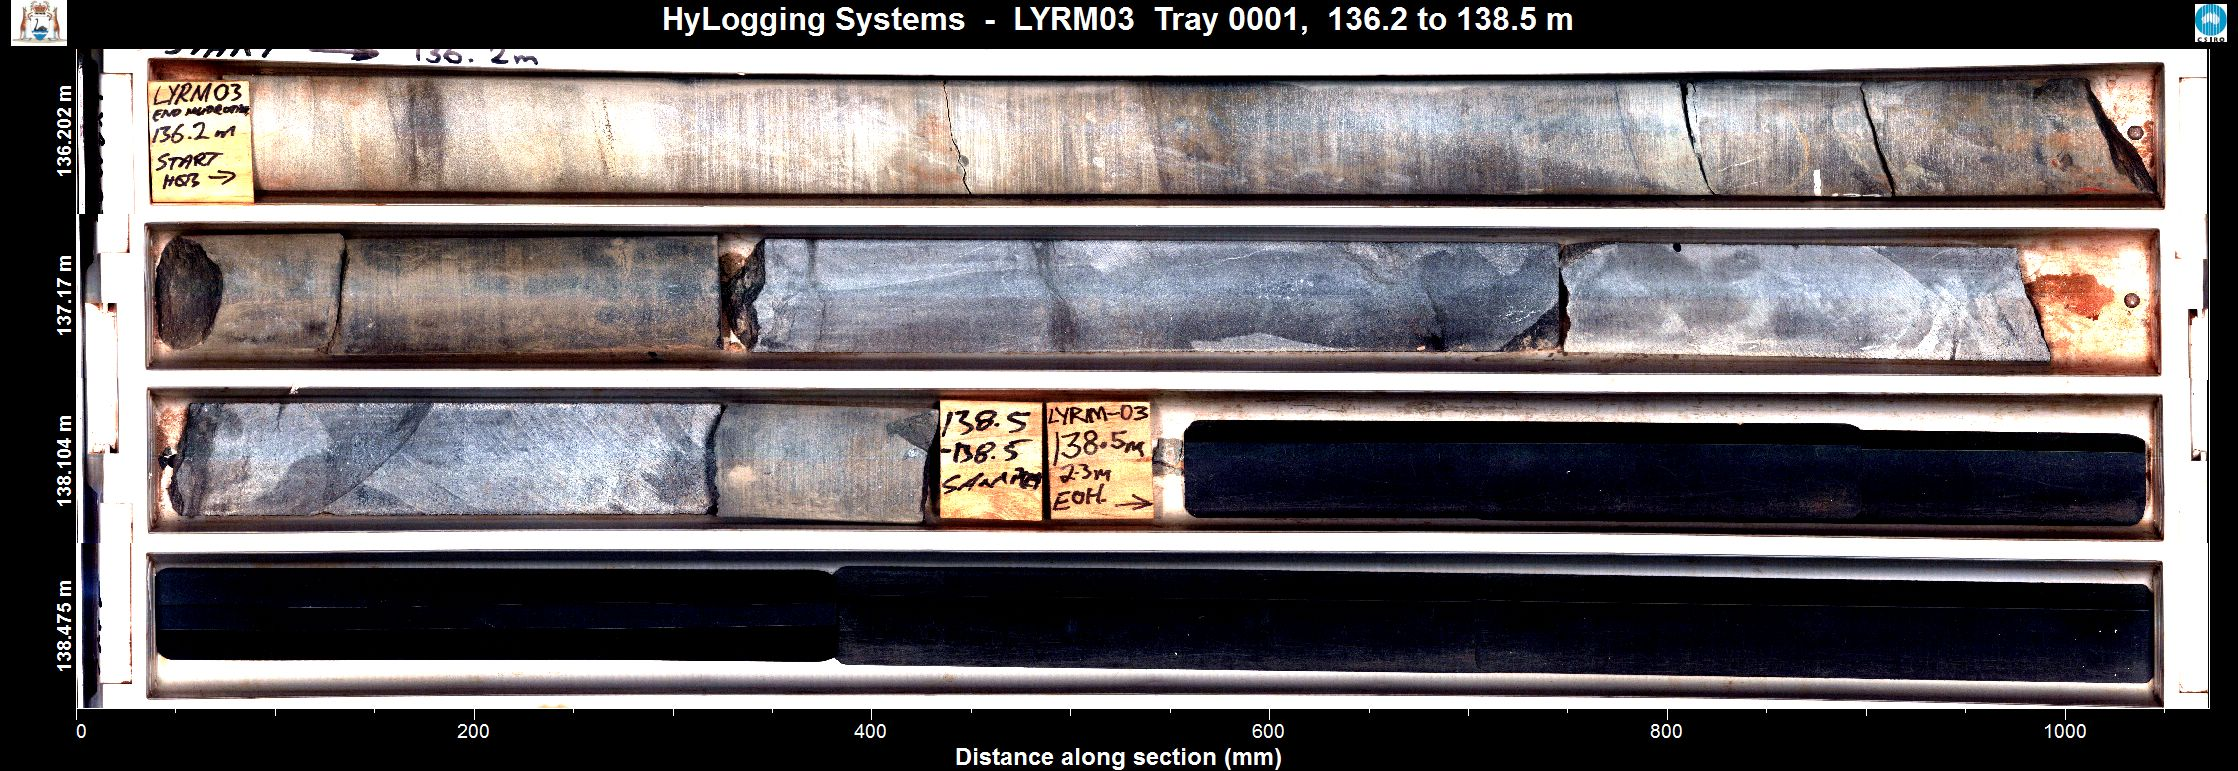

LYRM03 - tsg_mosaic


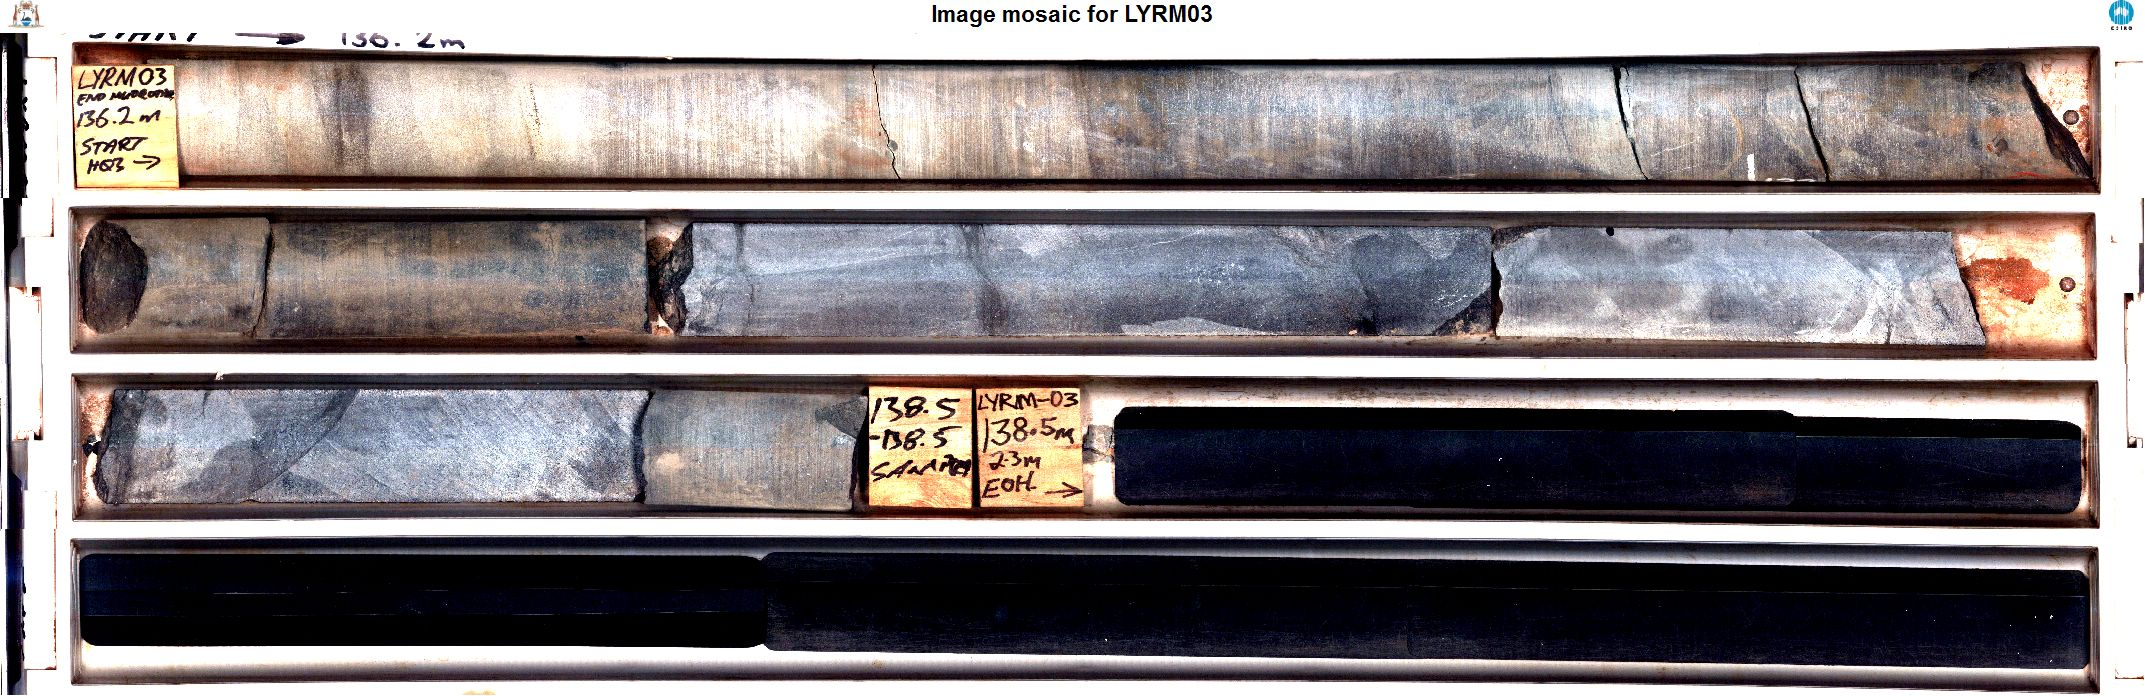

In [48]:
show_hole_image("LYRM03")
show_hole_image("LYRM03", image_type="tsg_mosaic")

In [73]:
# PHASE 2B — Spatial Enrichment

In [49]:
%pip install geopandas pyogrio shapely

Note: you may need to restart the kernel to use updated packages.


In [50]:
# ============================================================
# PHASE 2B — SPATIAL ENRICHMENT FOR ALL PROCESSED HOLES
#
# NO hard-coded hole names.
#
# 1. Automatically finds HyLogger spatial ZIP
# 2. Reads authoritative HyLogger drillhole spatial dataset
# 3. Automatically discovers every processed hole
# 4. Joins using COLLAR_ID
# 5. Retains lat/lon/elevation/processing level/geometry
# 6. Saves spatial metadata
# 7. Updates each hole metadata JSON
# 8. Provides on-demand hole-to-hole distance function
# ============================================================

from pathlib import Path
import geopandas as gpd
import pandas as pd
import numpy as np
import json
import math
import zipfile


# ============================================================
# 1. FIND HYLOGGER SPATIAL ZIP AUTOMATICALLY
# ============================================================

SPATIAL_DIR = PROJECT_ROOT / "data" / "spatial"

spatial_zips = list(
    SPATIAL_DIR.glob("*Hylogger*Drillholes*.zip")
)

if not spatial_zips:
    raise FileNotFoundError(
        "Could not find Hylogger Drillholes ZIP "
        f"in {SPATIAL_DIR}"
    )

spatial_zip = spatial_zips[0]

print("Spatial dataset:")
print(spatial_zip)


# ============================================================
# 2. EXTRACT SPATIAL DATASET IF REQUIRED
# ============================================================

spatial_extract_dir = (
    SPATIAL_DIR / "hylogger_drillholes"
)

spatial_extract_dir.mkdir(
    parents=True,
    exist_ok=True
)

# Extract only if shapefile is not already present
existing_shp = list(
    spatial_extract_dir.rglob("*.shp")
)

if not existing_shp:

    print("\nExtracting spatial dataset...")

    with zipfile.ZipFile(
        spatial_zip,
        "r"
    ) as z:

        z.extractall(
            spatial_extract_dir
        )

shapefiles = list(
    spatial_extract_dir.rglob("*.shp")
)

if not shapefiles:
    raise FileNotFoundError(
        "No shapefile found after extraction."
    )

shapefile_path = shapefiles[0]

print("\nShapefile:")
print(shapefile_path)


# ============================================================
# 3. READ AUTHORITATIVE HYLOGGER SPATIAL DATA
# ============================================================

hylogger_spatial = gpd.read_file(
    shapefile_path
)

print("\nSpatial records:", len(hylogger_spatial))

print("\nSpatial CRS:")
print(hylogger_spatial.crs)

print("\nAvailable columns:")
print(
    hylogger_spatial.columns.tolist()
)


# ============================================================
# 4. NORMALISE COLUMN NAMES
# ============================================================

hylogger_spatial.columns = [
    str(c).strip().upper()
    if c != "geometry"
    else "geometry"
    for c in hylogger_spatial.columns
]

# COLLAR_ID must be numeric for reliable joining
hylogger_spatial["COLLAR_ID"] = pd.to_numeric(
    hylogger_spatial["COLLAR_ID"],
    errors="coerce"
).astype("Int64")


# ============================================================
# 5. AUTOMATICALLY DISCOVER ALL PROCESSED HOLES
#
# We use the processed directories — no manually maintained list.
# ============================================================

processed_hole_names = [
    p.name
    for p in PROCESSED_ROOT.iterdir()
    if p.is_dir()
]

print(
    "\nProcessed hole folders found:",
    len(processed_hole_names)
)


# ============================================================
# 6. GET THEIR COLLAR IDs FROM NVCL CATALOGUE
# ============================================================

processed_catalog = (
    catalog[
        catalog["hole_name"].isin(
            processed_hole_names
        )
    ]
    [
        [
            "hole_name",
            "dataset",
            "source",
            "reference_number",
            "collar_id",
            "size_mb"
        ]
    ]
    .copy()
)

processed_catalog[
    "collar_id"
] = pd.to_numeric(
    processed_catalog["collar_id"],
    errors="coerce"
).astype("Int64")

processed_catalog = (
    processed_catalog
    .drop_duplicates(
        subset=["hole_name"]
    )
    .reset_index(drop=True)
)

print(
    "\nProcessed holes matched to catalogue:",
    len(processed_catalog)
)

display(
    processed_catalog.head(20)
)



Spatial dataset:
C:\Users\Meghana gundu\Desktop\hylogger\data\spatial\Hylogger_Drillholes_SHP.zip

Shapefile:
C:\Users\Meghana gundu\Desktop\hylogger\data\spatial\hylogger_drillholes\ESRI\SHAPEFILES\Hylogger_Drillholes.shp

Spatial records: 2009

Spatial CRS:
EPSG:7844

Available columns:
['DATA_NAME', 'WELL_NAME', 'PROC_LEVEL', 'SCAN_START', 'SCAN_END', 'SCAN_TOTAL', 'SCAN_DATE', 'SCDATE_TIR', 'SCDATE_MIR', 'LEV1_REL_D', 'LEV2_REL_D', 'COLLAR_ID', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'VERT_REF', 'DECFROMHOR', 'AZIMUTH', 'PROJECT', 'COMMODITY', 'DRILL_OPER', 'DRILL_DATE', 'REPORT_ID', 'REP_CONFID', 'TECT_NAME', 'SHORE_TYPE', 'TITLES', 'DATASET_ID', 'MOSAIC', 'SUM_HISTO', 'SUM_REPORT', 'MINERALLOG', 'GSWA_PXRF', 'GSWA_LIBS', 'ADD_ANALYS', 'EXT_PUB_1', 'EXT_PUB_2', 'EXT_PUB_3', 'EXTRACT_DA', 'geometry']

Processed hole folders found: 7

Processed holes matched to catalogue: 6


,hole_name,dataset,source,reference_number,collar_id,size_mb
0,LYRM01,LYRM01.zip,WAMEX,104799,3690554,10.860
1,LYRM03,LYRM03.zip,WAMEX,104799,3690556,10.390
2,LYRM06,LYRM06.zip,WAMEX,104799,3690559,10.650
3,LYRM09,LYRM09.zip,WAMEX,104799,3690562,11.360
4,PLWDD001,PLWDD001.zip,WAMEX,110741,3988628,10.780
5,PLWDD005,PLWDD005.zip,WAMEX,112432,3991007,9.509


In [51]:
# ============================================================
# PHASE 2B — CORRECTED SPATIAL MATCHING
#
# Join strategy:
# 1. Prefer COLLAR_ID where available
# 2. Fall back to WELL_NAME / DATA_NAME
#
# This works automatically for all processed holes.
# ============================================================


# ------------------------------------------------------------
# 1. PREPARE SPATIAL DATA
# ------------------------------------------------------------

spatial_lookup = hylogger_spatial.copy()

# Normalize names
spatial_lookup["WELL_NAME_KEY"] = (
    spatial_lookup["WELL_NAME"]
    .astype(str)
    .str.strip()
    .str.upper()
)

spatial_lookup["DATA_NAME_KEY"] = (
    spatial_lookup["DATA_NAME"]
    .astype(str)
    .str.strip()
    .str.upper()
)

spatial_lookup["COLLAR_ID_KEY"] = pd.to_numeric(
    spatial_lookup["COLLAR_ID"],
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 2. PREPARE PROCESSED CATALOG
# ------------------------------------------------------------

processed_catalog = processed_catalog.copy()

processed_catalog["HOLE_NAME_KEY"] = (
    processed_catalog["hole_name"]
    .astype(str)
    .str.strip()
    .str.upper()
)

processed_catalog["COLLAR_ID_KEY"] = pd.to_numeric(
    processed_catalog["collar_id"],
    errors="coerce"
).astype("Int64")


# ------------------------------------------------------------
# 3. MATCH EACH PROCESSED HOLE
#
# First attempt COLLAR_ID.
# If that fails, use WELL_NAME.
# If that fails, use DATA_NAME.
# ------------------------------------------------------------

spatial_records = []

for _, row in processed_catalog.iterrows():

    hole_name = row["hole_name"]
    hole_key = row["HOLE_NAME_KEY"]
    collar_id = row["COLLAR_ID_KEY"]

    match = pd.DataFrame()

    match_method = None

    # ----------------------------------------
    # Try COLLAR_ID first
    # ----------------------------------------

    if pd.notna(collar_id):

        match = spatial_lookup[
            spatial_lookup["COLLAR_ID_KEY"]
            ==
            collar_id
        ]

        if not match.empty:
            match_method = "collar_id"


    # ----------------------------------------
    # Fallback to WELL_NAME
    # ----------------------------------------

    if match.empty:

        match = spatial_lookup[
            spatial_lookup["WELL_NAME_KEY"]
            ==
            hole_key
        ]

        if not match.empty:
            match_method = "well_name"


    # ----------------------------------------
    # Fallback to DATA_NAME
    # ----------------------------------------

    if match.empty:

        match = spatial_lookup[
            spatial_lookup["DATA_NAME_KEY"]
            ==
            hole_key
        ]

        if not match.empty:
            match_method = "data_name"


    # ----------------------------------------
    # Store result
    # ----------------------------------------

    if match.empty:

        spatial_records.append({
            "hole_id": hole_name,
            "dataset": row["dataset"],
            "source": row["source"],
            "reference_number": row["reference_number"],
            "catalog_collar_id": (
                None
                if pd.isna(collar_id)
                else int(collar_id)
            ),

            "spatial_match_status": "not_matched",
            "spatial_match_method": None,

            "latitude": np.nan,
            "longitude": np.nan,
            "elevation_m": np.nan,

            "processing_level_authoritative": np.nan,
            "scan_start_authoritative_m": np.nan,
            "scan_end_authoritative_m": np.nan,

            "mosaic_reference": None,
            "mineral_log_reference": None,

            "geometry": None
        })

        continue


    # use first matching record
    s = match.iloc[0]

    spatial_records.append({

        "hole_id": hole_name,

        "dataset": row["dataset"],
        "source": row["source"],
        "reference_number": row["reference_number"],

        # Keep catalogue collar ID
        "catalog_collar_id": (
            None
            if pd.isna(collar_id)
            else int(collar_id)
        ),

        # Keep spatial collar ID separately
        "spatial_collar_id": (
            None
            if pd.isna(s["COLLAR_ID_KEY"])
            else int(s["COLLAR_ID_KEY"])
        ),

        "spatial_hole_name": s["WELL_NAME"],
        "spatial_data_name": s["DATA_NAME"],

        "latitude": s["LATITUDE"],
        "longitude": s["LONGITUDE"],
        "elevation_m": s["ELEVATION"],

        "processing_level_authoritative": s["PROC_LEVEL"],

        "scan_start_authoritative_m": s["SCAN_START"],
        "scan_end_authoritative_m": s["SCAN_END"],

        "mosaic_reference": s["MOSAIC"],
        "mineral_log_reference": s["MINERALLOG"],

        "spatial_match_status": "matched",
        "spatial_match_method": match_method,

        "geometry": s.geometry
    })


# ------------------------------------------------------------
# 4. BUILD FINAL SPATIAL TABLE
# ------------------------------------------------------------

hole_spatial = pd.DataFrame(
    spatial_records
)

print("\nSPATIAL MATCH SUMMARY")

print(
    hole_spatial[
        "spatial_match_status"
    ].value_counts(
        dropna=False
    )
)

print("\nMATCH METHODS")

print(
    hole_spatial[
        "spatial_match_method"
    ].value_counts(
        dropna=False
    )
)


display(
    hole_spatial[
        [
            "hole_id",
            "catalog_collar_id",
            "spatial_collar_id",
            "latitude",
            "longitude",
            "elevation_m",
            "processing_level_authoritative",
            "scan_start_authoritative_m",
            "scan_end_authoritative_m",
            "spatial_match_method",
            "spatial_match_status"
        ]
    ]
)


# ------------------------------------------------------------
# 5. SAVE CSV VERSION
# ------------------------------------------------------------

hole_spatial_csv = (
    PROCESSED_ROOT
    /
    "hole_spatial_metadata.csv"
)

hole_spatial.drop(
    columns=["geometry"],
    errors="ignore"
).to_csv(
    hole_spatial_csv,
    index=False
)

print("\nSaved spatial CSV:")
print(hole_spatial_csv)


# ------------------------------------------------------------
# 6. SAVE GEOSPATIAL VERSION
#
# We build a clean GeoDataFrame rather than writing the merged
# dataframe containing COLLAR_ID/collar_id name conflicts.
# ------------------------------------------------------------

hole_spatial_gdf = gpd.GeoDataFrame(
    hole_spatial.copy(),
    geometry="geometry",
    crs=hylogger_spatial.crs
)

spatial_gpkg = (
    PROCESSED_ROOT
    /
    "hole_spatial_metadata.gpkg"
)

hole_spatial_gdf.to_file(
    spatial_gpkg,
    layer="hylogger_holes",
    driver="GPKG",
    index=False
)

print("\nSaved GeoPackage:")
print(spatial_gpkg)


# ------------------------------------------------------------
# 7. UPDATE INDIVIDUAL HOLE METADATA
# ------------------------------------------------------------

for _, row in hole_spatial.iterrows():

    hole_id = row["hole_id"]

    hole_dir = (
        PROCESSED_ROOT
        /
        hole_id
    )

    metadata_files = list(
        hole_dir.glob(
            "*_metadata.json"
        )
    )

    if not metadata_files:

        metadata_files = list(
            hole_dir.glob(
                "*_provenance.json"
            )
        )

    if not metadata_files:
        continue

    metadata_path = metadata_files[0]

    try:

        with open(
            metadata_path,
            "r",
            encoding="utf-8"
        ) as f:

            metadata = json.load(f)

    except Exception:

        metadata = {}


    metadata["catalog_collar_id"] = (
        None
        if pd.isna(
            row["catalog_collar_id"]
        )
        else int(
            row["catalog_collar_id"]
        )
    )


    metadata["latitude"] = (
        None
        if pd.isna(
            row["latitude"]
        )
        else float(
            row["latitude"]
        )
    )


    metadata["longitude"] = (
        None
        if pd.isna(
            row["longitude"]
        )
        else float(
            row["longitude"]
        )
    )


    metadata["elevation_m"] = (
        None
        if pd.isna(
            row["elevation_m"]
        )
        else float(
            row["elevation_m"]
        )
    )


    metadata[
        "processing_level_authoritative"
    ] = (
        None
        if pd.isna(
            row["processing_level_authoritative"]
        )
        else int(
            row["processing_level_authoritative"]
        )
    )


    metadata["coordinate_source"] = (
        "Hylogger Drillholes spatial dataset"
    )


    metadata["coordinate_crs"] = (
        str(hylogger_spatial.crs)
    )


    metadata["coordinate_status"] = (
        row["spatial_match_status"]
    )


    metadata["spatial_match_method"] = (
        row["spatial_match_method"]
    )


    with open(
        metadata_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            metadata,
            f,
            indent=2
        )


# ------------------------------------------------------------
# 8. ON-DEMAND DISTANCE FUNCTION
#
# No giant pairwise table.
# ------------------------------------------------------------

def distance_between_holes(
    hole_a,
    hole_b
):

    a = hole_spatial[
        hole_spatial["hole_id"]
        .str.upper()
        ==
        str(hole_a).upper()
    ]

    b = hole_spatial[
        hole_spatial["hole_id"]
        .str.upper()
        ==
        str(hole_b).upper()
    ]


    if a.empty:

        raise ValueError(
            f"Hole not found: {hole_a}"
        )


    if b.empty:

        raise ValueError(
            f"Hole not found: {hole_b}"
        )


    a = a.iloc[0]
    b = b.iloc[0]


    if (
        pd.isna(a["latitude"])
        or pd.isna(a["longitude"])
        or pd.isna(b["latitude"])
        or pd.isna(b["longitude"])
    ):

        raise ValueError(
            "One or both holes have no valid coordinates."
        )


    R = 6371000.0


    lat1 = math.radians(
        float(a["latitude"])
    )

    lat2 = math.radians(
        float(b["latitude"])
    )


    dlat = math.radians(
        float(b["latitude"])
        -
        float(a["latitude"])
    )


    dlon = math.radians(
        float(b["longitude"])
        -
        float(a["longitude"])
    )


    h = (
        math.sin(dlat / 2) ** 2
        +
        math.cos(lat1)
        *
        math.cos(lat2)
        *
        math.sin(dlon / 2) ** 2
    )


    distance_m = (
        2
        *
        R
        *
        math.atan2(
            math.sqrt(h),
            math.sqrt(1 - h)
        )
    )


    return {
        "hole_a": hole_a,
        "hole_b": hole_b,

        "distance_m":
            round(distance_m, 2),

        "distance_km":
            round(distance_m / 1000, 3)
    }


print("\n" + "=" * 70)
print("PHASE 2B — SPATIAL ENRICHMENT COMPLETE")
print("=" * 70)

print(
    "Total processed holes:",
    len(hole_spatial)
)

print(
    "Matched:",
    (
        hole_spatial[
            "spatial_match_status"
        ]
        ==
        "matched"
    ).sum()
)

print(
    "Not matched:",
    (
        hole_spatial[
            "spatial_match_status"
        ]
        ==
        "not_matched"
    ).sum()
)


SPATIAL MATCH SUMMARY
spatial_match_status
matched    6
Name: count, dtype: int64

MATCH METHODS
spatial_match_method
well_name    6
Name: count, dtype: int64


,hole_id,catalog_collar_id,spatial_collar_id,latitude,longitude,elevation_m,processing_level_authoritative,scan_start_authoritative_m,scan_end_authoritative_m,spatial_match_method,spatial_match_status
0,LYRM01,3690554,None,-23.659818,114.977080,NaN,1,155.8,158.8,well_name,matched
1,LYRM03,3690556,None,-23.384209,114.972279,NaN,1,136.2,138.5,well_name,matched
2,LYRM06,3690559,None,-23.326561,114.916770,NaN,1,125.7,128.0,well_name,matched
3,LYRM09,3690562,None,-23.090752,114.922503,NaN,1,47.1,49.2,well_name,matched
4,PLWDD001,3988628,None,-27.254269,123.013444,NaN,1,115.0,119.9,well_name,matched
5,PLWDD005,3991007,None,-27.243027,122.974928,NaN,1,100.7,103.3,well_name,matched



Saved spatial CSV:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\hole_spatial_metadata.csv

Saved GeoPackage:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\hole_spatial_metadata.gpkg

PHASE 2B — SPATIAL ENRICHMENT COMPLETE
Total processed holes: 6
Matched: 6
Not matched: 0


In [52]:
# ============================================================
# PHASE 2C — INGESTION READINESS & CONFIDENTIALITY GATE
#
# Final preparation before Phase 3.
#
# - No hard-coded holes
# - Only OPEN FILE holes become eligible
# - Automatically checks processed outputs/assets
# - Derives hole-level confidence from process level
# - Creates one ingestion manifest for PostGIS + MinIO
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json


# ============================================================
# 1. CONFIDENTIALITY GATE
# ============================================================

def is_open_file(row):

    wamex = str(
        row.get(
            "wamex_confidentiality",
            ""
        )
    ).upper()

    wapims = str(
        row.get(
            "wapims_confidentiality",
            ""
        )
    ).upper()

    return (
        "OPEN FILE" in wamex
        or
        "OPEN FILE" in wapims
    )


catalog = catalog.copy()

catalog["is_open_file"] = catalog.apply(
    is_open_file,
    axis=1
)


print("FULL CATALOG:", len(catalog))

print(
    "OPEN FILE:",
    catalog["is_open_file"].sum()
)

print(
    "NOT ELIGIBLE:",
    (~catalog["is_open_file"]).sum()
)


# This is the ONLY catalogue Phase 3 automation should use
eligible_catalog = (
    catalog[
        catalog["is_open_file"]
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "\nEligible holes for automated ingestion:",
    len(eligible_catalog)
)


# ============================================================
# 2. AUTOMATICALLY DISCOVER PROCESSED HOLES
# ============================================================

processed_holes = [
    p.name
    for p in PROCESSED_ROOT.iterdir()
    if p.is_dir()
]

print(
    "\nProcessed hole directories:",
    len(processed_holes)
)


# ============================================================
# 3. BUILD INGESTION RECORD FOR EACH PROCESSED HOLE
# ============================================================

ingestion_records = []

for hole_id in processed_holes:

    hole_dir = (
        PROCESSED_ROOT
        /
        hole_id
    )

    raw_dir = (
        RAW_ROOT
        /
        hole_id
    )


    # --------------------------------------------------------
    # Match to catalogue
    # --------------------------------------------------------

    cat_match = eligible_catalog[
        eligible_catalog[
            "hole_name"
        ].astype(str).str.upper()
        ==
        hole_id.upper()
    ]


    # Processed folder exists but hole is not OPEN FILE
    if cat_match.empty:

        ingestion_records.append({

            "hole_id": hole_id,

            "eligible_for_ingestion": False,

            "eligibility_reason":
                "not_found_in_open_file_catalog",

            "ingestion_status":
                "blocked"

        })

        continue


    cat_row = cat_match.iloc[0]


    # --------------------------------------------------------
    # Spatial match
    # --------------------------------------------------------

    spatial_match = hole_spatial[
        hole_spatial[
            "hole_id"
        ].astype(str).str.upper()
        ==
        hole_id.upper()
    ]


    if not spatial_match.empty:

        spatial_row = (
            spatial_match.iloc[0]
        )

        latitude = (
            spatial_row.get(
                "latitude",
                np.nan
            )
        )

        longitude = (
            spatial_row.get(
                "longitude",
                np.nan
            )
        )

        process_level = (
            spatial_row.get(
                "processing_level_authoritative",
                np.nan
            )
        )

        spatial_status = (
            spatial_row.get(
                "spatial_match_status",
                "not_matched"
            )
        )

        spatial_match_method = (
            spatial_row.get(
                "spatial_match_method",
                None
            )
        )

    else:

        latitude = np.nan
        longitude = np.nan
        process_level = np.nan

        spatial_status = (
            "not_matched"
        )

        spatial_match_method = None


    # --------------------------------------------------------
    # Hole-level confidence
    # --------------------------------------------------------

    confidence_map = {
        0: "Low",
        1: "Medium",
        2: "High"
    }


    if pd.notna(process_level):

        try:

            process_level_int = int(
                process_level
            )

            confidence = (
                confidence_map.get(
                    process_level_int
                )
            )

        except Exception:

            process_level_int = None
            confidence = None

    else:

        process_level_int = None
        confidence = None


    # --------------------------------------------------------
    # Find processed spectra
    # --------------------------------------------------------

    spectra_files = list(
        hole_dir.rglob(
            "*.npz"
        )
    )

    spectra_available = (
        len(spectra_files) > 0
    )


    # --------------------------------------------------------
    # Find processed mineral/scalar CSVs
    # --------------------------------------------------------

    csv_files = list(
        hole_dir.rglob(
            "*.csv"
        )
    )

    scalar_available = any(
        (
            "scalar" in p.name.lower()
            or
            "mineral" in p.name.lower()
            or
            "sample" in p.name.lower()
        )
        for p in csv_files
    )


    # --------------------------------------------------------
    # Find images from RAW extracted package
    # --------------------------------------------------------

    image_extensions = {
        ".jpg",
        ".jpeg",
        ".png",
        ".tif",
        ".tiff",
        ".bmp"
    }

    image_files = []

    if raw_dir.exists():

        image_files = [
            p
            for p in raw_dir.rglob("*")
            if (
                p.is_file()
                and
                p.suffix.lower()
                in image_extensions
            )
        ]


    core_images = [
        p
        for p in image_files
        if (
            "mosaic"
            not in p.name.lower()
        )
    ]

    mosaic_images = [
        p
        for p in image_files
        if (
            "mosaic"
            in p.name.lower()
        )
    ]


    image_available = (
        len(core_images) > 0
    )

    mosaic_available = (
        len(mosaic_images) > 0
    )


    # --------------------------------------------------------
    # Profilometer detection
    #
    # We are only detecting it for now.
    # We are NOT processing it yet.
    # --------------------------------------------------------

    profilometer_candidates = []

    if raw_dir.exists():

        profilometer_candidates = [
            p
            for p in raw_dir.rglob("*")
            if (
                "profil" in p.name.lower()
                or
                "profile_log" in p.name.lower()
            )
        ]


    profilometer_available = (
        len(
            profilometer_candidates
        )
        > 0
    )


    # --------------------------------------------------------
    # Raw ZIP status
    # --------------------------------------------------------

    raw_zip_files = []

    if raw_dir.exists():

        raw_zip_files = list(
            raw_dir.rglob(
                "*.zip"
            )
        )


    raw_zip_available = (
        len(raw_zip_files) > 0
    )


    # --------------------------------------------------------
    # Source URL
    # --------------------------------------------------------

    dataset_name = str(
        cat_row["dataset"]
    )

    source_url = (
        BASE_DOWNLOAD_URL
        +
        "/"
        +
        dataset_name
    )


    # --------------------------------------------------------
    # MinIO target object keys
    #
    # These are only planned keys.
    # Nothing is uploaded yet.
    # --------------------------------------------------------

    spectra_object_key = (
        f"level1/{hole_id}/"
        f"spectral/{hole_id}_nir_spectra.npz"
        if spectra_available
        else None
    )

    images_prefix = (
        f"level1/{hole_id}/images/"
        if image_available
        else None
    )

    mosaic_prefix = (
        f"level1/{hole_id}/mosaics/"
        if mosaic_available
        else None
    )

    profilometer_prefix = (
        f"level1/{hole_id}/profilometer/"
        if profilometer_available
        else None
    )


    # --------------------------------------------------------
    # Readiness
    #
    # Don't require every optional asset.
    #
    # Core minimum:
    # OPEN FILE
    # + processed spectra
    # + structured/scalar output
    # + coordinates
    # --------------------------------------------------------

    coordinates_available = (
        pd.notna(latitude)
        and
        pd.notna(longitude)
    )


    ready_for_phase3 = (
        spectra_available
        and
        scalar_available
        and
        coordinates_available
    )


    # --------------------------------------------------------
    # Add manifest record
    # --------------------------------------------------------

    ingestion_records.append({

        "hole_id":
            hole_id,

        "dataset":
            dataset_name,

        "source":
            cat_row.get(
                "source"
            ),

        "reference_number":
            cat_row.get(
                "reference_number"
            ),

        "catalog_collar_id":
            cat_row.get(
                "collar_id"
            ),

        "wamex_confidentiality":
            cat_row.get(
                "wamex_confidentiality"
            ),

        "wapims_confidentiality":
            cat_row.get(
                "wapims_confidentiality"
            ),

        "eligible_for_ingestion":
            True,

        "eligibility_reason":
            "open_file",

        "source_url":
            source_url,

        "latitude":
            latitude,

        "longitude":
            longitude,

        "spatial_match_status":
            spatial_status,

        "spatial_match_method":
            spatial_match_method,

        "process_level":
            process_level_int,

        "confidence":
            confidence,

        "spectra_available":
            spectra_available,

        "scalar_available":
            scalar_available,

        "image_available":
            image_available,

        "mosaic_available":
            mosaic_available,

        "profilometer_available":
            profilometer_available,

        "raw_zip_available":
            raw_zip_available,

        "coordinates_available":
            coordinates_available,

        "spectra_object_key":
            spectra_object_key,

        "images_prefix":
            images_prefix,

        "mosaic_prefix":
            mosaic_prefix,

        "profilometer_prefix":
            profilometer_prefix,

        "ready_for_phase3":
            ready_for_phase3,

        # Phase 3 will update these
        "minio_status":
            "not_uploaded",

        "postgis_status":
            "not_loaded",

        "cleanup_status":
            "not_started",

        "ingestion_status":
            (
                "ready"
                if ready_for_phase3
                else "needs_review"
            )
    })


# ============================================================
# 4. CREATE INGESTION MANIFEST
# ============================================================

ingestion_manifest = pd.DataFrame(
    ingestion_records
)


print("\n" + "=" * 70)

print(
    "PHASE 2C — INGESTION READINESS"
)

print("=" * 70)


print(
    "\nTotal processed:",
    len(
        ingestion_manifest
    )
)


print(
    "Ready for Phase 3:",
    ingestion_manifest[
        "ready_for_phase3"
    ].sum()
)


print(
    "Needs review:",
    (
        ingestion_manifest["ready_for_phase3"]
        .fillna(False)
        .eq(False)
    ).sum()
)


display_columns = [
    "hole_id",
    "eligible_for_ingestion",
    "process_level",
    "confidence",
    "spectra_available",
    "scalar_available",
    "image_available",
    "mosaic_available",
    "profilometer_available",
    "coordinates_available",
    "ready_for_phase3"
]


display(
    ingestion_manifest[
        display_columns
    ]
)


# ============================================================
# 5. SAVE MANIFEST
# ============================================================

manifest_path = (
    PROCESSED_ROOT
    /
    "ingestion_manifest.csv"
)

ingestion_manifest.to_csv(
    manifest_path,
    index=False
)


print(
    "\nSaved ingestion manifest:"
)

print(
    manifest_path
)


# ============================================================
# 6. FINAL SAFETY CHECK
#
# No non-open-file hole should ever be Phase-3 ready.
# ============================================================

unsafe = ingestion_manifest[
    (
        ingestion_manifest[
            "eligible_for_ingestion"
        ]
        != True
    )
    &
    (
        ingestion_manifest[
            "ready_for_phase3"
        ]
        == True
    )
]


if len(unsafe) > 0:

    raise RuntimeError(
        "SAFETY CHECK FAILED: "
        "A non-open-file hole was marked ready."
    )


print(
    "\nConfidentiality safety check: PASS"
)

print(
    "Only OPEN FILE holes are eligible "
    "for Phase 3 ingestion."
)

FULL CATALOG: 1951
OPEN FILE: 1418
NOT ELIGIBLE: 533

Eligible holes for automated ingestion: 1418

Processed hole directories: 7

PHASE 2C — INGESTION READINESS

Total processed: 7
Ready for Phase 3: 6
Needs review: 1


,hole_id,eligible_for_ingestion,process_level,confidence,spectra_available,scalar_available,image_available,mosaic_available,profilometer_available,coordinates_available,ready_for_phase3
0,LYRM01,True,1.0,Medium,True,True,True,True,False,True,True
1,LYRM03,True,1.0,Medium,True,True,True,True,False,True,True
2,LYRM06,True,1.0,Medium,True,True,True,True,False,True,True
3,LYRM09,True,1.0,Medium,True,True,True,True,False,True,True
4,PLWDD001,True,1.0,Medium,True,True,True,True,False,True,True
5,PLWDD005,True,1.0,Medium,True,True,True,True,False,True,True
6,repo_export,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Saved ingestion manifest:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\ingestion_manifest.csv

Confidentiality safety check: PASS
Only OPEN FILE holes are eligible for Phase 3 ingestion.


In [53]:
# ============================================================
# PHASE 2D — REPOSITORY CONTRACT EXPORT
#
# PURPOSE:
# Convert existing processed Level-1 outputs into the
# CSV contract expected by the backend.
#
# IMPORTANT:
# - NO re-download
# - NO raw TSG re-processing
# - STRICT per-hole file matching
# - Reject numeric mineral IDs / TSG sentinel values
# - Pilot-first export: PLWDD005 only
# - Preserve spectrum_index for MinIO spectrum lookup
#
# OUTPUT:
#   data/processed/repo_export/holes.csv
#   data/processed/repo_export/measurements.csv
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

REPO_EXPORT_DIR = (
    PROCESSED_ROOT
    / "repo_export"
)

REPO_EXPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Repo export directory:")
print(REPO_EXPORT_DIR)


# ============================================================
# 2. PILOT-FIRST EXPORT
#
# For now export ONLY PLWDD005.
#
# Later, after PostGIS + MinIO are proven,
# remove this hole_id filter and export all ready holes.
# ============================================================

if "ingestion_manifest" not in globals():
    raise RuntimeError(
        "ingestion_manifest is not available. "
        "Run Phase 2C first."
    )


export_manifest = ingestion_manifest[
    (
        ingestion_manifest[
            "hole_id"
        ].astype(str).str.upper()
        ==
        "PLWDD005"
    )
    &
    (
        ingestion_manifest[
            "eligible_for_ingestion"
        ]
        ==
        True
    )
    &
    (
        ingestion_manifest[
            "ready_for_phase3"
        ]
        ==
        True
    )
].copy()


if export_manifest.empty:
    raise RuntimeError(
        "PLWDD005 is not available as a Phase-3-ready hole."
    )


print(
    "\nEligible pilot holes:",
    len(export_manifest)
)

display(
    export_manifest[
        [
            "hole_id",
            "process_level",
            "confidence",
            "coordinates_available",
            "ready_for_phase3"
        ]
    ]
)


# ============================================================
# 3. HELPER — FIND COLUMN
# ============================================================

def find_column(df, candidates):

    lookup = {
        str(c).strip().lower(): c
        for c in df.columns
    }

    for candidate in candidates:

        key = candidate.lower()

        if key in lookup:
            return lookup[key]

    return None


# ============================================================
# 4. HELPER — CLEAN TEXT
# ============================================================

def clean_text_series(series):

    result = series.copy()

    result = result.replace(
        r"^\s*$",
        np.nan,
        regex=True
    )

    result = result.replace(
        {
            "nan": np.nan,
            "NaN": np.nan,
            "None": np.nan,
            "NULL": np.nan
        }
    )

    return result


# ============================================================
# 5. HELPER — REMOVE NUMERIC TSG SENTINELS
# ============================================================

def remove_numeric_sentinels(df):

    df = df.copy()

    for col in df.columns:

        if pd.api.types.is_numeric_dtype(
            df[col]
        ):

            df.loc[
                df[col] < -1e30,
                col
            ] = np.nan

    return df


# ============================================================
# 6. HELPER — VALIDATE MINERAL COLUMN
#
# Mineral columns must contain decoded names,
# not mostly numeric IDs.
# ============================================================

def validate_mineral_column(
    df,
    col,
    hole_id,
    label
):

    if col is None:
        return

    values = clean_text_series(
        df[col]
    ).dropna()

    if values.empty:
        return


    numeric_test = pd.to_numeric(
        values,
        errors="coerce"
    )

    numeric_fraction = (
        numeric_test
        .notna()
        .mean()
    )


    if numeric_fraction > 0.5:

        preview = (
            values
            .astype(str)
            .drop_duplicates()
            .head(10)
            .tolist()
        )

        raise RuntimeError(
            f"\n{hole_id}: {label} column '{col}' "
            "appears to contain numeric class IDs "
            "rather than decoded mineral names.\n"
            f"Example values: {preview}\n"
            "Export stopped."
        )


# ============================================================
# 7. BUILD holes.csv
# ============================================================

hole_rows = []


for _, manifest_row in export_manifest.iterrows():

    hole_id = str(
        manifest_row[
            "hole_id"
        ]
    )


    spatial = hole_spatial[
        hole_spatial[
            "hole_id"
        ].astype(str).str.upper()
        ==
        hole_id.upper()
    ]


    if spatial.empty:

        raise RuntimeError(
            f"Spatial record missing for {hole_id}"
        )


    spatial = spatial.iloc[0]


    hole_rows.append({

        "hole_id":
            hole_id,

        "hole_name":
            hole_id,

        "latitude":
            spatial.get(
                "latitude",
                np.nan
            ),

        "longitude":
            spatial.get(
                "longitude",
                np.nan
            ),

        "easting":
            np.nan,

        "northing":
            np.nan,

        "elevation_m":
            spatial.get(
                "elevation_m",
                np.nan
            ),

        # Do not misuse scan_end as borehole length.
        "borehole_length_m":
            np.nan,

        # Temporary backend-compatible defaults
        "inclination_deg":
            -90.0,

        "azimuth_deg":
            0.0
    })


holes_export = pd.DataFrame(
    hole_rows
)


# ============================================================
# 8. VALIDATE holes.csv
# ============================================================

required_hole_columns = [
    "hole_id",
    "hole_name",
    "latitude",
    "longitude",
    "easting",
    "northing",
    "elevation_m",
    "borehole_length_m",
    "inclination_deg",
    "azimuth_deg"
]


missing_hole_columns = [
    c
    for c in required_hole_columns
    if c not in holes_export.columns
]


if missing_hole_columns:

    raise RuntimeError(
        "holes.csv missing columns: "
        + str(
            missing_hole_columns
        )
    )


if holes_export[
    [
        "latitude",
        "longitude"
    ]
].isna().any().any():

    raise RuntimeError(
        "Pilot hole has missing latitude/longitude."
    )


print(
    "\nHOLES EXPORT:"
)

display(
    holes_export
)


# ============================================================
# 9. BUILD measurements.csv
#
# One row per processed depth/sample.
#
# Full spectra remain in NPZ.
# spectrum_index links each measurement to the NPZ row.
# ============================================================

measurement_frames = []


for hole_id in holes_export[
    "hole_id"
]:

    hole_dir = (
        PROCESSED_ROOT
        /
        hole_id
    )


    # ========================================================
    # 9A. STRICT MINERAL FILE SELECTION
    # ========================================================

    expected_files = [
        hole_dir
        /
        f"{hole_id}_minerals_final.csv",

        hole_dir
        /
        f"{hole_id}_minerals.csv"
    ]


    mineral_path = None


    for candidate in expected_files:

        if candidate.exists():

            mineral_path = candidate
            break


    if mineral_path is None:

        matching_files = [
            p
            for p in hole_dir.glob(
                "*.csv"
            )
            if (
                "mineral"
                in p.name.lower()
                and
                hole_id.lower()
                in p.name.lower()
            )
        ]


        if matching_files:

            mineral_path = (
                matching_files[0]
            )


    if mineral_path is None:

        raise FileNotFoundError(
            f"No valid mineral CSV found for {hole_id}"
        )


    print(
        "\n" + "=" * 60
    )

    print(
        hole_id
    )

    print(
        "=" * 60
    )

    print(
        "Using mineral file:"
    )

    print(
        mineral_path
    )


    # ========================================================
    # 9B. LOAD MINERAL TABLE
    # ========================================================

    df = pd.read_csv(
        mineral_path
    )


    df = remove_numeric_sentinels(
        df
    )


    print(
        "Rows:",
        len(df)
    )


    # ========================================================
    # 9C. DETECT COLUMNS
    # ========================================================

    depth_col = find_column(
        df,
        [
            "depth_m",
            "depth",
            "D"
        ]
    )


    sample_col = find_column(
        df,
        [
            "sample_index",
            "sample"
        ]
    )


    spectrum_index_col = find_column(
        df,
        [
            "spectrum_index"
        ]
    )


    swir_col = find_column(
        df,
        [
            "primary_swir_mineral",
            "swir_mineral",
            "Min1 sTSAS",
            "min1_stsas",
            "mineral_swir"
        ]
    )


    vnir_col = find_column(
        df,
        [
            "primary_vnir_mineral",
            "vnir_mineral",
            "Min1 sTSAV",
            "min1_stsav",
            "mineral_vnir"
        ]
    )


    swir_quality_col = find_column(
        df,
        [
            "swir_quality",
            "quality_swir"
        ]
    )


    vnir_quality_col = find_column(
        df,
        [
            "vnir_quality",
            "quality_vnir"
        ]
    )


    generic_quality_col = find_column(
        df,
        [
            "quality",
            "quality_flag"
        ]
    )


    if depth_col is None:

        raise RuntimeError(
            f"{hole_id}: depth column not found.\n"
            f"Columns: {df.columns.tolist()}"
        )


    print(
        "\nDetected columns:"
    )

    print(
        " depth:",
        depth_col
    )

    print(
        " sample:",
        sample_col
    )

    print(
        " spectrum_index:",
        spectrum_index_col
    )

    print(
        " SWIR:",
        swir_col
    )

    print(
        " VNIR:",
        vnir_col
    )

    print(
        " SWIR quality:",
        swir_quality_col
    )

    print(
        " VNIR quality:",
        vnir_quality_col
    )


    # ========================================================
    # 9D. VALIDATE MINERAL COLUMNS
    # ========================================================

    validate_mineral_column(
        df,
        swir_col,
        hole_id,
        "SWIR mineral"
    )


    validate_mineral_column(
        df,
        vnir_col,
        hole_id,
        "VNIR mineral"
    )


    # ========================================================
    # 9E. CLEAN / SORT DEPTH
    # ========================================================

    work = df.copy()


    work[
        "depth_value"
    ] = pd.to_numeric(
        work[
            depth_col
        ],
        errors="coerce"
    )


    work = (
        work[
            work[
                "depth_value"
            ].notna()
        ]
        .sort_values(
            "depth_value"
        )
        .reset_index(
            drop=True
        )
    )


    if work.empty:

        raise RuntimeError(
            f"{hole_id}: no valid depth rows."
        )


    # ========================================================
    # 9F. BUILD DEPTH INTERVALS
    # ========================================================

    depths = work[
        "depth_value"
    ].to_numpy(
        dtype=float
    )


    if len(depths) == 1:

        depth_from = np.array(
            [
                depths[0]
            ]
        )

        depth_to = np.array(
            [
                depths[0]
            ]
        )

    else:

        midpoints = (
            depths[:-1]
            +
            depths[1:]
        ) / 2


        first_width = (
            depths[1]
            -
            depths[0]
        ) / 2


        last_width = (
            depths[-1]
            -
            depths[-2]
        ) / 2


        depth_from = np.concatenate(
            [
                [
                    depths[0]
                    -
                    first_width
                ],
                midpoints
            ]
        )


        depth_to = np.concatenate(
            [
                midpoints,
                [
                    depths[-1]
                    +
                    last_width
                ]
            ]
        )


    # ========================================================
    # 9G. EXTRACT MINERAL LABELS
    # ========================================================

    if swir_col is not None:

        mineral_1 = clean_text_series(
            work[
                swir_col
            ]
        )

    else:

        mineral_1 = pd.Series(
            [
                np.nan
            ]
            *
            len(work)
        )


    if vnir_col is not None:

        mineral_2 = clean_text_series(
            work[
                vnir_col
            ]
        )

    else:

        mineral_2 = pd.Series(
            [
                np.nan
            ]
            *
            len(work)
        )


    # ========================================================
    # 9H. QUALITY MAPPING
    # ========================================================

    def map_quality(value):

        if pd.isna(
            value
        ):

            return None


        value = str(
            value
        ).strip().lower()


        if value == "interpreted":

            return "ok"


        if value in {
            "uncertain_or_invalid",
            "uncertain",
            "invalid",
            "low_signal"
        }:

            return "low_signal"


        if value in {
            "missing",
            ""
        }:

            return "missing"


        return None


    quality_flags = []


    for i in range(
        len(work)
    ):

        states = []


        if swir_quality_col is not None:

            q = map_quality(
                work.iloc[i][
                    swir_quality_col
                ]
            )

            if q is not None:

                states.append(
                    q
                )


        if vnir_quality_col is not None:

            q = map_quality(
                work.iloc[i][
                    vnir_quality_col
                ]
            )

            if q is not None:

                states.append(
                    q
                )


        if generic_quality_col is not None:

            q = map_quality(
                work.iloc[i][
                    generic_quality_col
                ]
            )

            if q is not None:

                states.append(
                    q
                )


        if not states:

            m1 = (
                mineral_1.iloc[i]
            )

            m2 = (
                mineral_2.iloc[i]
            )


            if (
                pd.isna(m1)
                and
                pd.isna(m2)
            ):

                quality = (
                    "missing"
                )

            else:

                quality = (
                    "ok"
                )


        else:

            if (
                "ok"
                not in states
                and
                "missing"
                in states
            ):

                quality = (
                    "missing"
                )

            elif (
                "low_signal"
                in states
                and
                "ok"
                not in states
            ):

                quality = (
                    "low_signal"
                )

            else:

                quality = (
                    "ok"
                )


        quality_flags.append(
            quality
        )


    # ========================================================
    # 9I. BACKEND NUMERIC CONFIDENCE PROXY
    #
    # NOT the same as hole-level process confidence.
    # ========================================================

    measurement_confidence = [
        {
            "ok":
                1.0,

            "low_signal":
                0.5,

            "missing":
                0.0
        }[
            q
        ]

        for q in quality_flags
    ]


    # ========================================================
    # 9J. SAMPLE NUMBER
    # ========================================================

    if sample_col is not None:

        sample_no = pd.to_numeric(
            work[
                sample_col
            ],
            errors="coerce"
        )

    else:

        sample_no = pd.Series(
            np.arange(
                1,
                len(work) + 1
            )
        )


    # ========================================================
    # 9K. SPECTRUM INDEX
    #
    # Links this row to:
    # spectra[spectrum_index]
    #
    # in the NPZ file that will be stored in MinIO.
    # ========================================================

    if spectrum_index_col is not None:

        spectrum_index = pd.to_numeric(
            work[
                spectrum_index_col
            ],
            errors="coerce"
        )

    else:

        print(
            f"WARNING: {hole_id} has no explicit "
            "spectrum_index column. "
            "Using current processed row order as fallback."
        )

        spectrum_index = pd.Series(
            np.arange(
                len(work)
            ),
            index=work.index
        )


    # ========================================================
    # 9L. VALIDATE SPECTRUM INDEX
    # ========================================================

    if spectrum_index.isna().any():

        raise RuntimeError(
            f"{hole_id}: spectrum_index contains missing values."
        )


    if (
        spectrum_index
        <
        0
    ).any():

        raise RuntimeError(
            f"{hole_id}: spectrum_index contains negative values."
        )


    # ========================================================
    # 9M. BUILD MEASUREMENT TABLE
    # ========================================================

    measurement_df = pd.DataFrame({

        "hole_id":
            hole_id,

        "sample_no":
            sample_no,

        "spectrum_index":
            spectrum_index.astype(
                int
            ),

        "depth_from_m":
            depth_from,

        "depth_to_m":
            depth_to,

        "mineral_1":
            mineral_1.fillna(
                ""
            ),

        "mineral_1_pct":
            np.nan,

        "mineral_2":
            mineral_2.fillna(
                ""
            ),

        "mineral_2_pct":
            np.nan,

        "confidence":
            measurement_confidence,

        "quality_flag":
            quality_flags
    })


    # ========================================================
    # 9N. FINAL MINERAL SAFETY CHECK
    # ========================================================

    for mineral_col in [
        "mineral_1",
        "mineral_2"
    ]:

        values = (
            measurement_df[
                mineral_col
            ]
            .replace(
                "",
                np.nan
            )
            .dropna()
        )


        if not values.empty:

            numeric_test = pd.to_numeric(
                values,
                errors="coerce"
            )


            numeric_fraction = (
                numeric_test
                .notna()
                .mean()
            )


            if numeric_fraction > 0.5:

                raise RuntimeError(
                    f"{hole_id}: exported {mineral_col} "
                    "still appears mostly numeric. "
                    "Export stopped."
                )


        sentinel_detected = (
            measurement_df[
                mineral_col
            ]
            .astype(str)
            .str.contains(
                "-3402823",
                regex=False,
                na=False
            )
            .any()
        )


        if sentinel_detected:

            raise RuntimeError(
                f"{hole_id}: TSG no-data sentinel detected "
                f"in {mineral_col}. Export stopped."
            )


    measurement_frames.append(
        measurement_df
    )


# ============================================================
# 10. COMBINE MEASUREMENTS
# ============================================================

if not measurement_frames:

    raise RuntimeError(
        "No measurement rows were created."
    )


measurements_export = pd.concat(
    measurement_frames,
    ignore_index=True
)


# ============================================================
# 11. FINAL CONTRACT VALIDATION
# ============================================================

required_measurement_columns = [
    "hole_id",
    "sample_no",
    "spectrum_index",
    "depth_from_m",
    "depth_to_m",
    "mineral_1",
    "mineral_1_pct",
    "mineral_2",
    "mineral_2_pct",
    "confidence",
    "quality_flag"
]


missing_measurement_columns = [
    c
    for c in required_measurement_columns
    if c not in measurements_export.columns
]


if missing_measurement_columns:

    raise RuntimeError(
        "measurements.csv missing columns: "
        + str(
            missing_measurement_columns
        )
    )


# ============================================================
# 12. VALIDATE HOLE REFERENCES
# ============================================================

unknown_holes = set(
    measurements_export[
        "hole_id"
    ].unique()
) - set(
    holes_export[
        "hole_id"
    ].unique()
)


if unknown_holes:

    raise RuntimeError(
        "Measurements reference unknown holes: "
        + str(
            unknown_holes
        )
    )


# ============================================================
# 13. VALIDATE QUALITY FLAGS
# ============================================================

allowed_quality = {
    "ok",
    "low_signal",
    "missing"
}


found_quality = set(
    measurements_export[
        "quality_flag"
    ]
    .dropna()
    .unique()
)


invalid_quality = (
    found_quality
    -
    allowed_quality
)


if invalid_quality:

    raise RuntimeError(
        "Invalid quality flags: "
        + str(
            invalid_quality
        )
    )


# ============================================================
# 14. VALIDATE CONFIDENCE
# ============================================================

if not measurements_export[
    "confidence"
].between(
    0,
    1
).all():

    raise RuntimeError(
        "Measurement confidence must be between 0 and 1."
    )


# ============================================================
# 15. VALIDATE SPECTRUM INDEX UNIQUENESS / RANGE
#
# For the pilot we expect one spectrum row per measurement.
# ============================================================

if measurements_export[
    "spectrum_index"
].duplicated().any():

    print(
        "\nWARNING: duplicate spectrum_index values detected."
    )


print(
    "\nSpectrum index range:"
)

print(
    measurements_export[
        "spectrum_index"
    ].min(),
    "→",
    measurements_export[
        "spectrum_index"
    ].max()
)


# ============================================================
# 16. SAVE REPO-COMPATIBLE CSV FILES
# ============================================================

holes_path = (
    REPO_EXPORT_DIR
    /
    "holes.csv"
)

measurements_path = (
    REPO_EXPORT_DIR
    /
    "measurements.csv"
)


holes_export.to_csv(
    holes_path,
    index=False
)


measurements_export.to_csv(
    measurements_path,
    index=False
)


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "PHASE 2D — PILOT REPOSITORY EXPORT COMPLETE"
)

print(
    "=" * 70
)


print(
    "\nHoles exported:",
    len(
        holes_export
    )
)


print(
    "Measurement rows exported:",
    len(
        measurements_export
    )
)


print(
    "\nQuality summary:"
)

print(
    measurements_export[
        "quality_flag"
    ].value_counts(
        dropna=False
    )
)


print(
    "\nMineral 1 summary:"
)

print(
    measurements_export[
        "mineral_1"
    ]
    .replace(
        "",
        np.nan
    )
    .value_counts(
        dropna=False
    )
    .head(
        20
    )
)


print(
    "\nMineral 2 summary:"
)

print(
    measurements_export[
        "mineral_2"
    ]
    .replace(
        "",
        np.nan
    )
    .value_counts(
        dropna=False
    )
    .head(
        20
    )
)


print(
    "\nMeasurements per hole:"
)

print(
    measurements_export.groupby(
        "hole_id"
    ).size()
)


print(
    "\nholes.csv:"
)

print(
    holes_path
)


print(
    "\nmeasurements.csv:"
)

print(
    measurements_path
)


print(
    "\nSample hole:"
)

display(
    holes_export
)


print(
    "\nSample measurements:"
)

display(
    measurements_export.head(
        30
    )
)

Repo export directory:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\repo_export

Eligible pilot holes: 1


,hole_id,process_level,confidence,coordinates_available,ready_for_phase3
5,PLWDD005,1.0,Medium,True,True



HOLES EXPORT:


,hole_id,hole_name,latitude,longitude,easting,northing,elevation_m,borehole_length_m,inclination_deg,azimuth_deg
0,PLWDD005,PLWDD005,-27.243027,122.974928,NaN,NaN,NaN,NaN,-90.0,0.0



PLWDD005
Using mineral file:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\PLWDD005\PLWDD005_minerals_final.csv
Rows: 405

Detected columns:
 depth: depth_m
 sample: sample_index
 spectrum_index: None
 SWIR: min1_stsas
 VNIR: min1_stsav
 SWIR quality: None
 VNIR quality: None

Spectrum index range:
0 → 404

PHASE 2D — PILOT REPOSITORY EXPORT COMPLETE

Holes exported: 1
Measurement rows exported: 405

Quality summary:
quality_flag
missing    320
ok          85
Name: count, dtype: int64

Mineral 1 summary:
mineral_1
NaN                320
Kaolinite-WX        47
Kaolinite-PX        22
Dickite             15
Montmorillonite      1
Name: count, dtype: int64

Mineral 2 summary:
mineral_2
NaN         402
Goethite      3
Name: count, dtype: int64

Measurements per hole:
hole_id
PLWDD005    405
dtype: int64

holes.csv:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\repo_export\holes.csv

measurements.csv:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\repo_export\measu

,hole_id,hole_name,latitude,longitude,easting,northing,elevation_m,borehole_length_m,inclination_deg,azimuth_deg
0,PLWDD005,PLWDD005,-27.243027,122.974928,NaN,NaN,NaN,NaN,-90.0,0.0



Sample measurements:


,hole_id,sample_no,spectrum_index,depth_from_m,depth_to_m,mineral_1,mineral_1_pct,mineral_2,mineral_2_pct,confidence,quality_flag
0,PLWDD005,11.0,0,101.550004,101.550004,,NaN,,NaN,0.0,missing
1,PLWDD005,12.0,1,101.550004,101.550004,,NaN,,NaN,0.0,missing
2,PLWDD005,13.0,2,101.550004,101.550004,,NaN,,NaN,0.0,missing
3,PLWDD005,10.0,3,101.550004,101.550005,,NaN,,NaN,0.0,missing
4,PLWDD005,8.0,4,101.550005,101.550005,,NaN,,NaN,0.0,missing
5,PLWDD005,7.0,5,101.550005,101.550005,,NaN,,NaN,0.0,missing
6,PLWDD005,6.0,6,101.550005,101.550005,,NaN,,NaN,0.0,missing
7,PLWDD005,9.0,7,101.550005,101.550005,,NaN,,NaN,0.0,missing
8,PLWDD005,3.0,8,101.550005,101.550006,,NaN,,NaN,0.0,missing
9,PLWDD005,2.0,9,101.550006,101.550006,,NaN,,NaN,0.0,missing


In [70]:
# ============================================================
# PHASE 3C — PILOT INGESTION TO POSTGIS + MINIO
#
# PILOT: PLWDD005 ONLY
#
# Flow:
# 1. Load Phase 2D exports
# 2. Recover TRUE spectrum_index from samples.csv
# 3. Validate NPZ ↔ measurements mapping
# 4. Connect MinIO
# 5. Upload spectrum + images
# 6. Verify MinIO objects
# 7. Connect PostGIS
# 8. Create ingestion run
# 9. Upsert drillhole
# 10. Replace pilot measurements
# 11. Register spectral/image assets
# 12. Mark ingestion complete
#
# NO LOCAL CLEANUP YET
# ============================================================

from pathlib import Path
import os
import json
import numpy as np
import pandas as pd

from dotenv import load_dotenv
from minio import Minio
import psycopg


# ============================================================
# 1. PILOT CONFIGURATION
# ============================================================

HOLE_ID = "PLWDD005"

PROCESSING_VERSION = "phase3-pilot-v1"

MINIO_BUCKET = "hylogger"


# ============================================================
# 2. LOAD ENVIRONMENT VARIABLES
# ============================================================

ENV_PATH = PROJECT_ROOT / ".env"

if not ENV_PATH.exists():
    raise FileNotFoundError(
        f".env not found: {ENV_PATH}"
    )

load_dotenv(
    ENV_PATH,
    override=True
)


POSTGRES_DB = os.getenv(
    "POSTGRES_DB"
)

POSTGRES_USER = os.getenv(
    "POSTGRES_USER"
)

POSTGRES_PASSWORD = os.getenv(
    "POSTGRES_PASSWORD"
)


MINIO_ROOT_USER = os.getenv(
    "MINIO_ROOT_USER"
)

MINIO_ROOT_PASSWORD = os.getenv(
    "MINIO_ROOT_PASSWORD"
)


required_env = {
    "POSTGRES_DB": POSTGRES_DB,
    "POSTGRES_USER": POSTGRES_USER,
    "POSTGRES_PASSWORD": POSTGRES_PASSWORD,
    "MINIO_ROOT_USER": MINIO_ROOT_USER,
    "MINIO_ROOT_PASSWORD": MINIO_ROOT_PASSWORD
}


missing_env = [
    key
    for key, value in required_env.items()
    if not value
]


if missing_env:
    raise RuntimeError(
        f"Missing .env values: {missing_env}"
    )


print("Environment loaded successfully.")


# ============================================================
# 3. PHASE 2D EXPORT PATHS
# ============================================================

REPO_EXPORT_DIR = (
    PROCESSED_ROOT
    / "repo_export"
)

holes_path = (
    REPO_EXPORT_DIR
    / "holes.csv"
)

measurements_path = (
    REPO_EXPORT_DIR
    / "measurements.csv"
)


if not holes_path.exists():
    raise FileNotFoundError(
        holes_path
    )

if not measurements_path.exists():
    raise FileNotFoundError(
        measurements_path
    )


holes_df = pd.read_csv(
    holes_path
)

measurements_df = pd.read_csv(
    measurements_path
)


holes_df = holes_df[
    holes_df["hole_id"]
    .astype(str)
    .str.upper()
    ==
    HOLE_ID
].copy()


measurements_df = measurements_df[
    measurements_df["hole_id"]
    .astype(str)
    .str.upper()
    ==
    HOLE_ID
].copy()


print(
    "\nHole rows:",
    len(holes_df)
)

print(
    "Measurement rows:",
    len(measurements_df)
)


if len(holes_df) != 1:
    raise RuntimeError(
        f"Expected exactly one {HOLE_ID} hole row."
    )


if measurements_df.empty:
    raise RuntimeError(
        f"No measurements found for {HOLE_ID}."
    )


# ============================================================
# 4. RECOVER TRUE SPECTRUM INDEX
#
# IMPORTANT:
#
# Phase 2D had no explicit spectrum_index in the mineral CSV.
# It therefore used processed row order.
#
# We now recover the original spectrum_index from the
# authoritative processed samples table.
# ============================================================

hole_processed_dir = (
    PROCESSED_ROOT
    / HOLE_ID
)


sample_files = [
    hole_processed_dir
    / f"{HOLE_ID}_samples.csv"
]


sample_path = None

for candidate in sample_files:

    if candidate.exists():
        sample_path = candidate
        break


if sample_path is None:
    raise FileNotFoundError(
        f"{HOLE_ID}_samples.csv not found."
    )


samples_df = pd.read_csv(
    sample_path
)


print(
    "\nUsing sample mapping:"
)

print(
    sample_path
)


required_sample_cols = {
    "sample_index",
    "spectrum_index"
}


if not required_sample_cols.issubset(
    samples_df.columns
):

    raise RuntimeError(
        "samples.csv must contain "
        "sample_index and spectrum_index.\n"
        f"Found columns: {samples_df.columns.tolist()}"
    )


samples_mapping = (
    samples_df[
        [
            "sample_index",
            "spectrum_index"
        ]
    ]
    .copy()
)


samples_mapping[
    "sample_index"
] = pd.to_numeric(
    samples_mapping[
        "sample_index"
    ],
    errors="coerce"
)


samples_mapping[
    "spectrum_index"
] = pd.to_numeric(
    samples_mapping[
        "spectrum_index"
    ],
    errors="coerce"
)


if samples_mapping[
    "sample_index"
].duplicated().any():

    raise RuntimeError(
        "sample_index is not unique in samples.csv."
    )


# ============================================================
# 5. REPLACE FALLBACK SPECTRUM INDEX
#
# measurement.sample_no came from sample_index.
# ============================================================

measurements_df[
    "sample_no"
] = pd.to_numeric(
    measurements_df[
        "sample_no"
    ],
    errors="coerce"
)


measurements_df = (
    measurements_df
    .drop(
        columns=[
            "spectrum_index"
        ],
        errors="ignore"
    )
    .merge(
        samples_mapping,
        left_on="sample_no",
        right_on="sample_index",
        how="left",
        validate="many_to_one"
    )
)


if measurements_df[
    "spectrum_index"
].isna().any():

    bad = measurements_df[
        measurements_df[
            "spectrum_index"
        ].isna()
    ]

    display(
        bad.head()
    )

    raise RuntimeError(
        "Some measurements could not be mapped "
        "to their true spectrum_index."
    )


measurements_df[
    "spectrum_index"
] = measurements_df[
    "spectrum_index"
].astype(int)


# sample_index duplicate column no longer needed
measurements_df = measurements_df.drop(
    columns=[
        "sample_index"
    ],
    errors="ignore"
)


print(
    "\nTrue spectrum index recovered."
)

print(
    "Spectrum index range:",
    measurements_df[
        "spectrum_index"
    ].min(),
    "→",
    measurements_df[
        "spectrum_index"
    ].max()
)


# ============================================================
# 6. FIND NPZ SPECTRAL FILE
# ============================================================

npz_candidates = list(
    hole_processed_dir.glob(
        "*nir_spectra.npz"
    )
)


if not npz_candidates:

    npz_candidates = list(
        hole_processed_dir.glob(
            "*.npz"
        )
    )


if not npz_candidates:

    raise FileNotFoundError(
        f"No NPZ spectrum file found for {HOLE_ID}."
    )


spectra_path = (
    npz_candidates[0]
)


print(
    "\nSpectrum file:"
)

print(
    spectra_path
)


# ============================================================
# 7. VALIDATE NPZ CONTENT
# ============================================================

with np.load(
    spectra_path,
    allow_pickle=False
) as npz_data:

    print(
        "\nNPZ keys:",
        npz_data.files
    )


    if "spectra" not in npz_data.files:

        raise RuntimeError(
            "NPZ has no 'spectra' array."
        )


    spectra_array = npz_data[
        "spectra"
    ]


    n_samples = (
        spectra_array.shape[0]
    )


    n_bands = (
        spectra_array.shape[1]
        if spectra_array.ndim > 1
        else None
    )


print(
    "Spectrum matrix shape:",
    spectra_array.shape
)


print(
    "Measurements:",
    len(measurements_df)
)


if measurements_df[
    "spectrum_index"
].max() >= n_samples:

    raise RuntimeError(
        "A measurement spectrum_index exceeds "
        "the number of NPZ spectrum rows."
    )


if len(measurements_df) != n_samples:

    print(
        "\nWARNING:"
        " measurement count does not equal NPZ row count."
    )


# ============================================================
# 8. SAVE CORRECTED measurements.csv
#
# This replaces the fallback spectrum index with the actual one.
# ============================================================

measurements_df.to_csv(
    measurements_path,
    index=False
)


print(
    "\nCorrected measurements.csv saved."
)


# ============================================================
# 9. FIND CORE IMAGES
# ============================================================

hole_raw_dir = (
    RAW_ROOT
    / HOLE_ID
)


image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp"
}


image_files = [
    p
    for p in hole_raw_dir.rglob("*")
    if (
        p.is_file()
        and
        p.suffix.lower()
        in image_extensions
    )
]


if not image_files:

    raise RuntimeError(
        f"No images found for {HOLE_ID}."
    )


core_images = [
    p
    for p in image_files
    if "mosaic" not in p.name.lower()
]


mosaic_images = [
    p
    for p in image_files
    if "mosaic" in p.name.lower()
]


print(
    "\nCore images:",
    len(core_images)
)

for p in core_images:
    print(
        " ",
        p.name
    )


print(
    "\nMosaics:",
    len(mosaic_images)
)

for p in mosaic_images:
    print(
        " ",
        p.name
    )


# ============================================================
# 10. CONNECT TO MINIO
# ============================================================

minio_client = Minio(

    "localhost:9000",

    access_key=MINIO_ROOT_USER,

    secret_key=MINIO_ROOT_PASSWORD,

    secure=False
)


if not minio_client.bucket_exists(
    MINIO_BUCKET
):

    minio_client.make_bucket(
        MINIO_BUCKET
    )

    print(
        "\nCreated MinIO bucket:",
        MINIO_BUCKET
    )

else:

    print(
        "\nMinIO bucket exists:",
        MINIO_BUCKET
    )


# ============================================================
# 11. DEFINE MINIO OBJECT KEYS
# ============================================================

spectral_object_key = (
    f"level1/"
    f"{HOLE_ID}/"
    f"spectral/"
    f"{spectra_path.name}"
)


image_uploads = []


for image_path in core_images:

    object_key = (
        f"level1/"
        f"{HOLE_ID}/"
        f"images/"
        f"{image_path.name}"
    )

    image_uploads.append(
        {
            "path":
                image_path,

            "asset_type":
                "core_image",

            "object_key":
                object_key
        }
    )


for image_path in mosaic_images:

    object_key = (
        f"level1/"
        f"{HOLE_ID}/"
        f"mosaics/"
        f"{image_path.name}"
    )

    image_uploads.append(
        {
            "path":
                image_path,

            "asset_type":
                "tsg_mosaic",

            "object_key":
                object_key
        }
    )


# ============================================================
# 12. CONNECT TO POSTGIS
# ============================================================

conn = psycopg.connect(

    host="localhost",

    port=5432,

    dbname=POSTGRES_DB,

    user=POSTGRES_USER,

    password=POSTGRES_PASSWORD
)


print(
    "\nConnected to PostGIS."
)


# ============================================================
# 13. HELPER — NORMALISE DATABASE VALUES
# ============================================================

def db_value(value):

    if pd.isna(
        value
    ):
        return None

    if isinstance(
        value,
        np.generic
    ):
        return value.item()

    return value


# ============================================================
# 14. CREATE INGESTION RUN
# ============================================================

ingestion_run_id = None


with conn.cursor() as cur:

    cur.execute(
        """
        INSERT INTO ingestion_run
        (
            hole_id,
            processing_version,
            status,
            minio_status,
            postgis_status,
            cleanup_status
        )
        VALUES
        (
            %s,
            %s,
            'started',
            'pending',
            'pending',
            'not_started'
        )
        RETURNING ingestion_run_id
        """,
        (
            HOLE_ID,
            PROCESSING_VERSION
        )
    )


    ingestion_run_id = (
        cur.fetchone()[0]
    )


conn.commit()


print(
    "\nIngestion run:",
    ingestion_run_id
)


# ============================================================
# 15. PERFORM PILOT INGESTION
# ============================================================

try:

    # ========================================================
    # 15A. UPLOAD SPECTRAL NPZ TO MINIO
    # ========================================================

    print(
        "\nUploading spectral object..."
    )


    minio_client.fput_object(

        MINIO_BUCKET,

        spectral_object_key,

        str(
            spectra_path
        )
    )


    # Verify
    spectral_stat = (
        minio_client.stat_object(
            MINIO_BUCKET,
            spectral_object_key
        )
    )


    print(
        "Uploaded:",
        spectral_object_key
    )

    print(
        "Size:",
        spectral_stat.size,
        "bytes"
    )


    # ========================================================
    # 15B. UPLOAD IMAGES
    # ========================================================

    print(
        "\nUploading images..."
    )


    for item in image_uploads:

        minio_client.fput_object(

            MINIO_BUCKET,

            item[
                "object_key"
            ],

            str(
                item[
                    "path"
                ]
            )
        )


        stat = minio_client.stat_object(

            MINIO_BUCKET,

            item[
                "object_key"
            ]
        )


        print(
            "Uploaded:",
            item[
                "object_key"
            ],
            "|",
            stat.size,
            "bytes"
        )


    # ========================================================
    # 15C. MARK MINIO COMPLETE
    # ========================================================

    with conn.cursor() as cur:

        cur.execute(
            """
            UPDATE ingestion_run
            SET
                minio_status = 'uploaded',
                status = 'processing'
            WHERE ingestion_run_id = %s
            """,
            (
                ingestion_run_id,
            )
        )


    conn.commit()


    # ========================================================
    # 15D. GET HOLE METADATA
    # ========================================================

    hole = (
        holes_df.iloc[0]
    )


    manifest_match = ingestion_manifest[
        ingestion_manifest[
            "hole_id"
        ].astype(str).str.upper()
        ==
        HOLE_ID
    ]


    if manifest_match.empty:

        raise RuntimeError(
            "Pilot hole missing from ingestion_manifest."
        )


    manifest_row = (
        manifest_match.iloc[0]
    )


    spatial_match = hole_spatial[
        hole_spatial[
            "hole_id"
        ].astype(str).str.upper()
        ==
        HOLE_ID
    ]


    if spatial_match.empty:

        raise RuntimeError(
            "Pilot hole missing from hole_spatial."
        )


    spatial_row = (
        spatial_match.iloc[0]
    )


    # ========================================================
    # 15E. POSTGIS TRANSACTION
    # ========================================================

    with conn.transaction():

        with conn.cursor() as cur:

            # ------------------------------------------------
            # UPSERT DRILLHOLE
            # ------------------------------------------------

            cur.execute(
                """
                INSERT INTO drillhole
                (
                    hole_id,
                    hole_name,

                    latitude,
                    longitude,

                    elevation_m,
                    borehole_length_m,

                    inclination_deg,
                    azimuth_deg,

                    geom,

                    catalog_collar_id,

                    source,
                    reference_number,

                    wamex_confidentiality,
                    wapims_confidentiality,

                    process_level,
                    process_confidence,

                    spatial_match_status,
                    spatial_match_method,

                    processing_version,

                    updated_at
                )

                VALUES
                (
                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    ST_SetSRID(
                        ST_MakePoint(
                            %s,
                            %s
                        ),
                        4326
                    ),

                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    %s,

                    NOW()
                )

                ON CONFLICT (hole_id)

                DO UPDATE SET

                    hole_name =
                        EXCLUDED.hole_name,

                    latitude =
                        EXCLUDED.latitude,

                    longitude =
                        EXCLUDED.longitude,

                    elevation_m =
                        EXCLUDED.elevation_m,

                    borehole_length_m =
                        EXCLUDED.borehole_length_m,

                    inclination_deg =
                        EXCLUDED.inclination_deg,

                    azimuth_deg =
                        EXCLUDED.azimuth_deg,

                    geom =
                        EXCLUDED.geom,

                    catalog_collar_id =
                        EXCLUDED.catalog_collar_id,

                    source =
                        EXCLUDED.source,

                    reference_number =
                        EXCLUDED.reference_number,

                    wamex_confidentiality =
                        EXCLUDED.wamex_confidentiality,

                    wapims_confidentiality =
                        EXCLUDED.wapims_confidentiality,

                    process_level =
                        EXCLUDED.process_level,

                    process_confidence =
                        EXCLUDED.process_confidence,

                    spatial_match_status =
                        EXCLUDED.spatial_match_status,

                    spatial_match_method =
                        EXCLUDED.spatial_match_method,

                    processing_version =
                        EXCLUDED.processing_version,

                    updated_at =
                        NOW()
                """,

                (

                    HOLE_ID,

                    db_value(
                        hole[
                            "hole_name"
                        ]
                    ),

                    db_value(
                        hole[
                            "latitude"
                        ]
                    ),

                    db_value(
                        hole[
                            "longitude"
                        ]
                    ),

                    db_value(
                        hole[
                            "elevation_m"
                        ]
                    ),

                    db_value(
                        hole[
                            "borehole_length_m"
                        ]
                    ),

                    db_value(
                        hole[
                            "inclination_deg"
                        ]
                    ),

                    db_value(
                        hole[
                            "azimuth_deg"
                        ]
                    ),

                    # longitude
                    db_value(
                        hole[
                            "longitude"
                        ]
                    ),

                    # latitude
                    db_value(
                        hole[
                            "latitude"
                        ]
                    ),

                    db_value(
                        manifest_row.get(
                            "catalog_collar_id"
                        )
                    ),

                    db_value(
                        manifest_row.get(
                            "source"
                        )
                    ),

                    str(
                        manifest_row.get(
                            "reference_number"
                        )
                    )
                    if pd.notna(
                        manifest_row.get(
                            "reference_number"
                        )
                    )
                    else None,

                    db_value(
                        manifest_row.get(
                            "wamex_confidentiality"
                        )
                    ),

                    db_value(
                        manifest_row.get(
                            "wapims_confidentiality"
                        )
                    ),

                    db_value(
                        manifest_row.get(
                            "process_level"
                        )
                    ),

                    db_value(
                        manifest_row.get(
                            "confidence"
                        )
                    ),

                    db_value(
                        spatial_row.get(
                            "spatial_match_status"
                        )
                    ),

                    db_value(
                        spatial_row.get(
                            "spatial_match_method"
                        )
                    ),

                    PROCESSING_VERSION
                )
            )


            # ------------------------------------------------
            # IDEMPOTENT RELOAD
            #
            # Remove previous pilot observations/assets
            # before inserting the current version.
            # ------------------------------------------------

            cur.execute(
                """
                DELETE FROM measurement
                WHERE hole_id = %s
                """,
                (
                    HOLE_ID,
                )
            )


            cur.execute(
                """
                DELETE FROM spectral_asset
                WHERE hole_id = %s
                """,
                (
                    HOLE_ID,
                )
            )


            cur.execute(
                """
                DELETE FROM image_asset
                WHERE hole_id = %s
                """,
                (
                    HOLE_ID,
                )
            )


            # ------------------------------------------------
            # INSERT MEASUREMENTS
            # ------------------------------------------------

            measurement_values = []


            for _, row in measurements_df.iterrows():

                measurement_values.append(
                    (

                        HOLE_ID,

                        db_value(
                            row[
                                "sample_no"
                            ]
                        ),

                        db_value(
                            row[
                                "spectrum_index"
                            ]
                        ),

                        db_value(
                            row[
                                "depth_from_m"
                            ]
                        ),

                        db_value(
                            row[
                                "depth_to_m"
                            ]
                        ),

                        (
                            None
                            if pd.isna(
                                row[
                                    "mineral_1"
                                ]
                            )
                            or str(
                                row[
                                    "mineral_1"
                                ]
                            ).strip() == ""
                            else str(
                                row[
                                    "mineral_1"
                                ]
                            )
                        ),

                        db_value(
                            row[
                                "mineral_1_pct"
                            ]
                        ),

                        (
                            None
                            if pd.isna(
                                row[
                                    "mineral_2"
                                ]
                            )
                            or str(
                                row[
                                    "mineral_2"
                                ]
                            ).strip() == ""
                            else str(
                                row[
                                    "mineral_2"
                                ]
                            )
                        ),

                        db_value(
                            row[
                                "mineral_2_pct"
                            ]
                        ),

                        db_value(
                            row[
                                "quality_flag"
                            ]
                        ),

                        db_value(
                            row[
                                "confidence"
                            ]
                        )
                    )
                )


            cur.executemany(
                """
                INSERT INTO measurement
                (
                    hole_id,
                    sample_no,
                    spectrum_index,

                    depth_from_m,
                    depth_to_m,

                    mineral_1,
                    mineral_1_pct,

                    mineral_2,
                    mineral_2_pct,

                    quality_flag,
                    confidence
                )

                VALUES
                (
                    %s,
                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s,

                    %s,
                    %s
                )
                """,
                measurement_values
            )


            # ------------------------------------------------
            # REGISTER SPECTRAL ASSET
            # ------------------------------------------------

            cur.execute(
                """
                INSERT INTO spectral_asset
                (
                    hole_id,
                    spectral_type,
                    n_samples,
                    n_bands,
                    file_format,
                    minio_bucket,
                    object_key,
                    source_format
                )

                VALUES
                (
                    %s,
                    'NIR',
                    %s,
                    %s,
                    'NPZ',
                    %s,
                    %s,
                    'TSG'
                )
                """,
                (
                    HOLE_ID,
                    int(
                        n_samples
                    ),
                    int(
                        n_bands
                    ),
                    MINIO_BUCKET,
                    spectral_object_key
                )
            )


            # ------------------------------------------------
            # REGISTER IMAGE ASSETS
            # ------------------------------------------------

            for item in image_uploads:

                cur.execute(
                    """
                    INSERT INTO image_asset
                    (
                        hole_id,
                        asset_type,
                        filename,
                        minio_bucket,
                        object_key,
                        depth_from_m,
                        depth_to_m
                    )

                    VALUES
                    (
                        %s,
                        %s,
                        %s,
                        %s,
                        %s,
                        NULL,
                        NULL
                    )
                    """,

                    (
                        HOLE_ID,

                        item[
                            "asset_type"
                        ],

                        item[
                            "path"
                        ].name,

                        MINIO_BUCKET,

                        item[
                            "object_key"
                        ]
                    )
                )


    # ========================================================
    # 15F. MARK INGESTION COMPLETED
    # ========================================================

    with conn.cursor() as cur:

        cur.execute(
            """
            UPDATE ingestion_run
            SET
                status = 'completed',
                minio_status = 'uploaded',
                postgis_status = 'loaded',
                cleanup_status = 'not_started',
                completed_at = NOW()
            WHERE ingestion_run_id = %s
            """,
            (
                ingestion_run_id,
            )
        )


    conn.commit()


except Exception as e:

    conn.rollback()


    try:

        with conn.cursor() as cur:

            cur.execute(
                """
                UPDATE ingestion_run
                SET
                    status = 'failed',
                    error_message = %s,
                    completed_at = NOW()
                WHERE ingestion_run_id = %s
                """,
                (
                    str(
                        e
                    )[:5000],

                    ingestion_run_id
                )
            )


        conn.commit()


    except Exception:

        conn.rollback()


    raise


# ============================================================
# 16. VERIFY POSTGIS
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "POSTGIS VERIFICATION"
)

print(
    "=" * 70
)


with conn.cursor() as cur:

    cur.execute(
        """
        SELECT
            hole_id,
            latitude,
            longitude,
            process_level,
            process_confidence,
            ST_AsText(geom),
            processing_version
        FROM drillhole
        WHERE hole_id = %s
        """,
        (
            HOLE_ID,
        )
    )


    drillhole_result = (
        cur.fetchone()
    )


    print(
        "\nDrillhole:"
    )

    print(
        drillhole_result
    )


    cur.execute(
        """
        SELECT COUNT(*)
        FROM measurement
        WHERE hole_id = %s
        """,
        (
            HOLE_ID,
        )
    )


    measurement_count = (
        cur.fetchone()[0]
    )


    print(
        "\nMeasurements:",
        measurement_count
    )


    cur.execute(
        """
        SELECT
            MIN(spectrum_index),
            MAX(spectrum_index),
            COUNT(DISTINCT spectrum_index)
        FROM measurement
        WHERE hole_id = %s
        """,
        (
            HOLE_ID,
        )
    )


    spectrum_index_check = (
        cur.fetchone()
    )


    print(
        "Spectrum index check:",
        spectrum_index_check
    )


    cur.execute(
        """
        SELECT
            spectral_type,
            n_samples,
            n_bands,
            minio_bucket,
            object_key
        FROM spectral_asset
        WHERE hole_id = %s
        """,
        (
            HOLE_ID,
        )
    )


    spectral_assets = (
        cur.fetchall()
    )


    print(
        "\nSpectral assets:"
    )

    for row in spectral_assets:
        print(
            row
        )


    cur.execute(
        """
        SELECT
            asset_type,
            filename,
            minio_bucket,
            object_key
        FROM image_asset
        WHERE hole_id = %s
        ORDER BY asset_type
        """,
        (
            HOLE_ID,
        )
    )


    image_assets = (
        cur.fetchall()
    )


    print(
        "\nImage assets:"
    )

    for row in image_assets:
        print(
            row
        )


    cur.execute(
        """
        SELECT
            status,
            minio_status,
            postgis_status,
            cleanup_status,
            processing_version
        FROM ingestion_run
        WHERE ingestion_run_id = %s
        """,
        (
            ingestion_run_id,
        )
    )


    ingestion_status = (
        cur.fetchone()
    )


    print(
        "\nIngestion run:"
    )

    print(
        ingestion_status
    )


# ============================================================
# 17. VERIFY MINIO OBJECTS
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "MINIO VERIFICATION"
)

print(
    "=" * 70
)


objects_to_check = [
    spectral_object_key
] + [
    item[
        "object_key"
    ]
    for item in image_uploads
]


for object_key in objects_to_check:

    stat = (
        minio_client.stat_object(
            MINIO_BUCKET,
            object_key
        )
    )

    print(
        object_key,
        "→",
        stat.size,
        "bytes"
    )


# ============================================================
# 18. FINAL PILOT VALIDATION
# ============================================================

expected_measurements = (
    len(
        measurements_df
    )
)


if measurement_count != expected_measurements:

    raise RuntimeError(
        f"Measurement count mismatch: "
        f"expected {expected_measurements}, "
        f"found {measurement_count}."
    )


if spectrum_index_check[0] < 0:

    raise RuntimeError(
        "Invalid minimum spectrum_index."
    )


if spectrum_index_check[1] >= n_samples:

    raise RuntimeError(
        "Invalid maximum spectrum_index."
    )


print(
    "\n" + "=" * 70
)

print(
    "PHASE 3C — PILOT INGESTION COMPLETE"
)

print(
    "=" * 70
)


print(
    "\nHole:",
    HOLE_ID
)

print(
    "Measurements:",
    measurement_count
)

print(
    "Spectrum rows:",
    n_samples
)

print(
    "Spectrum bands:",
    n_bands
)

print(
    "Images:",
    len(
        image_uploads
    )
)

print(
    "PostGIS: OK"
)

print(
    "MinIO: OK"
)

print(
    "\nLOCAL FILES HAVE NOT BEEN DELETED."
)

print(
    "Cleanup will only be introduced after "
    "pilot verification."
)


# ============================================================
# 19. CLOSE POSTGRES CONNECTION
# ============================================================

conn.close()

Environment loaded successfully.

Hole rows: 1
Measurement rows: 405

Using sample mapping:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\PLWDD005\PLWDD005_samples.csv

True spectrum index recovered.
Spectrum index range: 0 → 404

Spectrum file:
C:\Users\Meghana gundu\Desktop\hylogger\data\processed\PLWDD005\PLWDD005_nir_spectra.npz

NPZ keys: ['wavelengths', 'spectra']
Spectrum matrix shape: (405, 531)
Measurements: 405

Corrected measurements.csv saved.

Core images: 1
  PLWDD005_0001.jpg

Mosaics: 1
  PLWDD005_tsg_Mosaic.jpg

MinIO bucket exists: hylogger

Connected to PostGIS.

Ingestion run: 1

Uploading spectral object...
Uploaded: level1/PLWDD005/spectral/PLWDD005_nir_spectra.npz
Size: 749369 bytes

Uploading images...
Uploaded: level1/PLWDD005/images/PLWDD005_0001.jpg | 697201 bytes
Uploaded: level1/PLWDD005/mosaics/PLWDD005_tsg_Mosaic.jpg | 124715 bytes

POSTGIS VERIFICATION

Drillhole:
('PLWDD005', -27.24302722, 122.974928, 1, 'Medium', 'POINT(122.974928 -27.24302722

In [55]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd

from dotenv import load_dotenv
from minio import Minio
import psycopg

OperationalError: connection failed: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "hylogger_user"
Multiple connection attempts failed. All failures were:
- host: 'localhost', port: 5432, hostaddr: '::1': connection failed: connection to server at "::1", port 5432 failed: FATAL:  password authentication failed for user "hylogger_user"
- host: 'localhost', port: 5432, hostaddr: '127.0.0.1': connection failed: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "hylogger_user"

OperationalError: connection failed: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "hylogger_user"

PROJECT_ROOT: C:\Users\Meghana gundu\Desktop\hylogger
.env exists: True
.env path: C:\Users\Meghana gundu\Desktop\hylogger\.env
DB: 'hylogger'
USER: 'hylogger_user'
PASSWORD SET: True
PASSWORD LENGTH: 8


OperationalError: connection failed: connection to server at "127.0.0.1", port 5432 failed: FATAL:  password authentication failed for user "hylogger_user"

In [69]:
import psycopg
import os

test_conn = psycopg.connect(
    host="127.0.0.1",
    port=5432,
    dbname=os.getenv("POSTGRES_DB"),
    user=os.getenv("POSTGRES_USER"),
    password=os.getenv("POSTGRES_PASSWORD")
)

print("PostGIS connection successful ✅")

test_conn.close()

PostGIS connection successful ✅


In [2]:
print("h")

h
